In [ ]:
import json

file_path = "known_exploited_vulnerabilities.json"

with open(file_path, "r", encoding="utf-8") as file:
    data = json.load(file)

print("Total vulnerabilities:", len(data["vulnerabilities"]))
print("First record:")
print(data["vulnerabilities"][0])

Total vulnerabilities: 1781
First record:
{'cveID': 'CVE-2026-114713', 'vendorProject': 'UnrealIRCd', 'product': 'UnrealIRCd', 'vulnerabilityName': 'UnrealIRCd Improper Neutralization of Delimiters Vulnerability', 'dateAdded': '2026-11-13', 'shortDescription': 'UnrealIRCd UnrealIRCd contains an improper neutralization of delimiters vulnerability that allows any user on a network with two or more linked servers to inject server-to-server commands that are executed with server authority.', 'requiredAction': "Apply mitigations in accordance with vendor instructions, ensuring compliance with CISA’s BOD 26-04 Prioritizing Security Updates Based on Risk (see URL in Notes) guidance and CISA’s “Forensics Triage Requirements” (see URL in Notes). Follow applicable BOD 26-04 guidance for cloud services or discontinue use of the product if mitigations are unavailable. Stakeholders are responsible for evaluating each asset's internet exposure and ensuring adherence to BOD 26-04 patching guidelines.

In [ ]:
import pandas as pd
# Convert JSON vulnerability records into DataFrame
df_kev = pd.DataFrame(data["vulnerabilities"])

# Dataset overview
print("Dataset Shape:", df_kev.shape)

Dataset Shape: (1781, 12)


In [ ]:
# Column names
print("\nColumns:")
print(df_kev.columns.tolist())


Columns:
['cveID', 'vendorProject', 'product', 'vulnerabilityName', 'dateAdded', 'shortDescription', 'requiredAction', 'dueDate', 'knownRansomwareCampaignUse', 'forensicTriage', 'notes', 'cwes']


In [ ]:
# First 5 records
display(df_kev.head())

,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes
0,CVE-2026-114713,UnrealIRCd,UnrealIRCd,UnrealIRCd Improper Neutralization of Delimite...,2026-11-13,UnrealIRCd UnrealIRCd contains an improper neu...,Apply mitigations in accordance with vendor in...,2026-11-16,Unknown,Yes,https://forums.unrealircd.org/viewtopic.php?t=...,[CWE-140]
1,CVE-2026-123039,Check Point,Multiple Products,Check Point Multiple Products Incorrect Permis...,2026-11-13,"Check Point Firewall, Multi-Domain Security Ma...",Apply mitigations in accordance with vendor in...,2026-11-16,Unknown,Yes,https://support.checkpoint.com/results/sk/sk10...,"[CWE-732, CWE-862]"
2,CVE-2026-124194,Microsoft,Office,Microsoft Office Outlook Missing User Interact...,2026-11-10,Microsoft Office Outlook contains a missing us...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://msrc.microsoft.com/update-guide/en-US/...,[CWE-356]
3,CVE-2026-111793,Openwave Messaging Limited,Webtop Media Transcoder,Openwave Messaging Limited Webtop Media Transc...,2026-11-10,Openwave Messaging Limited Webtop Media Transc...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://github.com/GISOpenwave/security-adviso...,[CWE-669]
4,CVE-2026-20320,Cisco,BroadWorks,Cisco BroadWorks Improper Restriction of XML E...,2026-11-10,Cisco BroadWorks contains an improper restrict...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://sec.cloudapps.cisco.com/security/cente...,[CWE-611]


In [ ]:
df_kev.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1781 entries, 0 to 1780
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   cveID                       1781 non-null   object
 1   vendorProject               1781 non-null   object
 2   product                     1781 non-null   object
 3   vulnerabilityName           1781 non-null   object
 4   dateAdded                   1781 non-null   object
 5   shortDescription            1781 non-null   object
 6   requiredAction              1781 non-null   object
 7   dueDate                     1781 non-null   object
 8   knownRansomwareCampaignUse  1781 non-null   object
 9   forensicTriage              1781 non-null   object
 10  notes                       1781 non-null   object
 11  cwes                        1781 non-null   object
dtypes: object(12)
memory usage: 167.1+ KB


In [ ]:
# Missing values
display(df_kev.isnull().sum())

,0
cveID,0
vendorProject,0
product,0
vulnerabilityName,0
dateAdded,0
shortDescription,0
requiredAction,0
dueDate,0
knownRansomwareCampaignUse,0
forensicTriage,0


In [ ]:
import pandas as pd

df_veris = pd.read_csv("vcdb.csv", low_memory=False)

print("Dataset Shape:", df_veris.shape)
print("Total Rows:", len(df_veris))
print("Total Columns:", len(df_veris.columns))

Dataset Shape: (1178, 2514)
Total Rows: 1178
Total Columns: 2514


In [ ]:
# Missing values
missing = df_veris.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": (missing / len(df_veris)) * 100
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report.head(30))

,Missing_Count,Missing_Percentage
asset.assets.amount.M - SIM card,1178,100.0
asset.assets.amount.M - Fax,1178,100.0
asset.assets.amount.E - Unknown,1178,100.0
asset.assets.amount.E - Telemetry,1178,100.0
asset.assets.amount.E - Telematics,1178,100.0
asset.assets.amount.E - Other,1178,100.0
actor.partner.name,1178,100.0
asset.assets.amount.N - Public WAN,1178,100.0
asset.assets.amount.N - Private WAN,1178,100.0
asset.assets.amount.N - PBX,1178,100.0


In [ ]:
# Count columns based on missing-value percentage

total_columns = len(df_veris.columns)

all_missing = df_veris.isna().all().sum()

partially_missing = (
    df_veris.isna().any() & df_veris.notna().any()
).sum()

complete_columns = df_veris.notna().all().sum()

print("Total Columns:", total_columns)
print("Completely Empty Columns:", all_missing)
print("Partially Missing Columns:", partially_missing)
print("Complete Columns:", complete_columns)

Total Columns: 2514
Completely Empty Columns: 164
Partially Missing Columns: 723
Complete Columns: 1627


In [ ]:
keywords = [
    "incident", "date", "actor", "victim",
    "industry", "asset", "action", "discovery",
    "impact", "pattern", "malware", "vector",
    "country", "region", "security"
]

for keyword in keywords:

    matches = [
        col for col in df_veris.columns
        if keyword.lower() in col.lower()
    ]

    print(f"\n{keyword.upper()} ({len(matches)} columns):")
    print(matches[:20])


INCIDENT (12 columns):
['discovery_method.external.variety.Incident response', 'discovery_method.internal.variety.Incident response', 'discovery_method.partner.variety.Incident response', 'incident_id', 'security_incident.Confirmed', 'security_incident.False positive', 'security_incident.Near miss', 'security_incident.Suspected', 'timeline.incident.day', 'timeline.incident.month', 'timeline.incident.time', 'timeline.incident.year']

DATE (1 columns):
['action.malware.vector.Software update']

ACTOR (599 columns):
['actor.external.country.AD', 'actor.external.country.AE', 'actor.external.country.AF', 'actor.external.country.AG', 'actor.external.country.AI', 'actor.external.country.AL', 'actor.external.country.AM', 'actor.external.country.AO', 'actor.external.country.AQ', 'actor.external.country.AR', 'actor.external.country.AS', 'actor.external.country.AT', 'actor.external.country.AU', 'actor.external.country.AW', 'actor.external.country.AX', 'actor.external.country.AZ', 'actor.external

In [ ]:
keywords = [
    "incident", "date", "actor", "victim",
    "industry", "asset", "action", "discovery",
    "impact", "pattern", "malware", "vector",
    "country", "region", "security"
]

for keyword in keywords:

    matches = [
        col for col in df_veris.columns
        if keyword.lower() in col.lower()
    ]

    print(f"\n{keyword.upper()} ({len(matches)} columns):")
    print(matches[:20])


INCIDENT (12 columns):
['discovery_method.external.variety.Incident response', 'discovery_method.internal.variety.Incident response', 'discovery_method.partner.variety.Incident response', 'incident_id', 'security_incident.Confirmed', 'security_incident.False positive', 'security_incident.Near miss', 'security_incident.Suspected', 'timeline.incident.day', 'timeline.incident.month', 'timeline.incident.time', 'timeline.incident.year']

DATE (1 columns):
['action.malware.vector.Software update']

ACTOR (599 columns):
['actor.external.country.AD', 'actor.external.country.AE', 'actor.external.country.AF', 'actor.external.country.AG', 'actor.external.country.AI', 'actor.external.country.AL', 'actor.external.country.AM', 'actor.external.country.AO', 'actor.external.country.AQ', 'actor.external.country.AR', 'actor.external.country.AS', 'actor.external.country.AT', 'actor.external.country.AU', 'actor.external.country.AW', 'actor.external.country.AX', 'actor.external.country.AZ', 'actor.external

In [ ]:
pattern_cols = [
    col for col in df_veris.columns
    if col.startswith("pattern.")
]

pattern_summary = pd.DataFrame({
    "Attack_Pattern": pattern_cols,
    "Incident_Count": [
        df_veris[col].eq(True).sum()
        for col in pattern_cols
    ]
})

pattern_summary = pattern_summary.sort_values(
    by="Incident_Count",
    ascending=False
)

display(pattern_summary)

,Attack_Pattern,Incident_Count
1,pattern.Miscellaneous Errors,278
4,pattern.System Intrusion,221
2,pattern.Lost and Stolen Assets,189
0,pattern.Privilege Misuse,182
3,pattern.Basic Web Application Attacks,148
7,pattern.Everything Else,116
5,pattern.Social Engineering,60
6,pattern.Denial of Service,23


In [ ]:
# Create a working copy
df_veris_clean = df_veris.copy()

# Remove columns that contain only missing values
df_veris_clean = df_veris_clean.dropna(axis=1, how="all")

print("Original Shape:", df_veris.shape)
print("Cleaned Shape:", df_veris_clean.shape)

print("Columns Removed:",
      df_veris.shape[1] - df_veris_clean.shape[1])

Original Shape: (1178, 2514)
Cleaned Shape: (1178, 2350)
Columns Removed: 164


In [ ]:
print("Duplicate Rows:",
      df_veris_clean.duplicated().sum())

print("Missing Incident IDs:",
      df_veris_clean["incident_id"].isna().sum())

print("Unique Incident IDs:",
      df_veris_clean["incident_id"].nunique())

print("\nDuplicate Incident IDs:",
      df_veris_clean["incident_id"].duplicated().sum())

Duplicate Rows: 1
Missing Incident IDs: 0
Unique Incident IDs: 1163

Duplicate Incident IDs: 15


In [ ]:
# Important analytical columns
selected_columns = [
    "incident_id",
    "timeline.incident.year",
    "timeline.incident.month",
    "timeline.incident.day",
    "Actor",
    "victim.industry",
    "victim.industry2",
    "victim.region",
    "security_incident.Confirmed",
    "security_incident.Suspected",
    "security_incident.False positive",
    "security_incident.Near miss"
]

# Add all attack pattern columns
selected_columns += [
    col for col in df_veris_clean.columns
    if col.startswith("pattern.")
]

# Keep only columns available in the dataset
selected_columns = [
    col for col in selected_columns
    if col in df_veris_clean.columns
]

df_veris_analysis = df_veris_clean[selected_columns].copy()

print("Analytical Dataset Shape:",
      df_veris_analysis.shape)

display(df_veris_analysis.head())

Analytical Dataset Shape: (1178, 20)


,incident_id,timeline.incident.year,timeline.incident.month,timeline.incident.day,Actor,victim.industry,victim.industry2,victim.region,security_incident.Confirmed,security_incident.Suspected,security_incident.False positive,security_incident.Near miss,pattern.Privilege Misuse,pattern.Miscellaneous Errors,pattern.Lost and Stolen Assets,pattern.Basic Web Application Attacks,pattern.System Intrusion,pattern.Social Engineering,pattern.Denial of Service,pattern.Everything Else
0,0001AA7F-C601-424A-B2B8-BE6C9F5164E7,2010.0,4.0,9.0,Internal,923140.0,92.0,019021,True,False,False,False,True,False,False,False,False,False,False,False
1,0eb22d90-8e87-11ec-a600-657ec2694f8f,2020.0,NaN,NaN,Internal,541511.0,54.0,150039,True,False,False,False,False,True,False,False,False,False,False,False
2,0008DADB-E83D-4278-A19A-CEE01610CF43,2014.0,NaN,NaN,External,621111.0,62.0,019021,True,False,False,False,False,False,True,False,False,False,False,False
3,000D403E-2DC9-4EA7-9294-BD3938D1C3C7,2014.0,NaN,NaN,Partner,622110.0,62.0,019021,True,False,False,False,False,False,True,False,False,False,False,False
4,0012CC25-9167-40D8-8FE3-3D0DFD8FB6BB,2012.0,NaN,NaN,External,51919.0,51.0,150154,True,False,False,False,False,False,False,True,False,False,False,False


In [ ]:
# Convert date components into numeric values
for col in [
    "timeline.incident.year",
    "timeline.incident.month",
    "timeline.incident.day"
]:
    df_veris_analysis[col] = pd.to_numeric(
        df_veris_analysis[col],
        errors="coerce"
    )

# Create incident date
df_veris_analysis["Incident_Date"] = pd.to_datetime(
    {
        "year": df_veris_analysis["timeline.incident.year"],
        "month": df_veris_analysis["timeline.incident.month"],
        "day": df_veris_analysis["timeline.incident.day"]
    },
    errors="coerce"
)

# Year-wise incident count
yearly_incidents = (
    df_veris_analysis
    .groupby("timeline.incident.year")["incident_id"]
    .nunique()
    .reset_index(name="Incident_Count")
)

display(yearly_incidents)

,timeline.incident.year,Incident_Count
0,1971.0,1
1,1998.0,1
2,2001.0,1
3,2003.0,1
4,2004.0,1
5,2005.0,3
6,2006.0,6
7,2007.0,8
8,2008.0,7
9,2009.0,11


In [ ]:
df_veris_final = df_veris_analysis.copy()

print("Dataset Shape:", df_veris_final.shape)
print("\nCurrent Column Names:")
print(df_veris_final.columns.tolist())

Dataset Shape: (1178, 21)

Current Column Names:
['incident_id', 'timeline.incident.year', 'timeline.incident.month', 'timeline.incident.day', 'Actor', 'victim.industry', 'victim.industry2', 'victim.region', 'security_incident.Confirmed', 'security_incident.Suspected', 'security_incident.False positive', 'security_incident.Near miss', 'pattern.Privilege Misuse', 'pattern.Miscellaneous Errors', 'pattern.Lost and Stolen Assets', 'pattern.Basic Web Application Attacks', 'pattern.System Intrusion', 'pattern.Social Engineering', 'pattern.Denial of Service', 'pattern.Everything Else', 'Incident_Date']


In [ ]:
rename_columns = {
    "incident_id": "Incident_ID",
    "timeline.incident.year": "Incident_Year",
    "timeline.incident.month": "Incident_Month",
    "timeline.incident.day": "Incident_Day",
    "Actor": "Actor",
    "victim.industry": "Victim_Industry",
    "victim.industry2": "Victim_Industry_Secondary",
    "victim.region": "Victim_Region",
    "security_incident.Confirmed": "Incident_Confirmed",
    "security_incident.Suspected": "Incident_Suspected",
    "security_incident.False positive": "False_Positive",
    "security_incident.Near miss": "Near_Miss"
}

df_veris_final = df_veris_final.rename(columns=rename_columns)

# Rename attack pattern columns
pattern_columns = {
    col: "Pattern_" + col.replace("pattern.", "").replace(" ", "_")
    for col in df_veris_final.columns
    if col.startswith("pattern.")
}

df_veris_final = df_veris_final.rename(columns=pattern_columns)

print("Updated Column Names:")
print(df_veris_final.columns.tolist())

Updated Column Names:
['Incident_ID', 'Incident_Year', 'Incident_Month', 'Incident_Day', 'Actor', 'Victim_Industry', 'Victim_Industry_Secondary', 'Victim_Region', 'Incident_Confirmed', 'Incident_Suspected', 'False_Positive', 'Near_Miss', 'Pattern_Privilege_Misuse', 'Pattern_Miscellaneous_Errors', 'Pattern_Lost_and_Stolen_Assets', 'Pattern_Basic_Web_Application_Attacks', 'Pattern_System_Intrusion', 'Pattern_Social_Engineering', 'Pattern_Denial_of_Service', 'Pattern_Everything_Else', 'Incident_Date']


In [ ]:
print("Current Data Types:")

display(
    pd.DataFrame({
        "Column": df_veris_final.columns,
        "Data_Type": df_veris_final.dtypes.astype(str).values,
        "Missing_Values": df_veris_final.isnull().sum().values,
        "Unique_Values": df_veris_final.nunique().values
    })
)

Current Data Types:


,Column,Data_Type,Missing_Values,Unique_Values
0,Incident_ID,object,0,1163
1,Incident_Year,float64,1,25
2,Incident_Month,float64,306,12
3,Incident_Day,float64,664,31
4,Actor,object,27,4
5,Victim_Industry,float64,1,309
6,Victim_Industry_Secondary,float64,1,24
7,Victim_Region,object,2,40
8,Incident_Confirmed,bool,0,2
9,Incident_Suspected,bool,0,2


In [ ]:
# Check actual values in important columns

columns_to_check = [
    "Actor",
    "Victim_Industry",
    "Victim_Industry_Secondary",
    "Victim_Region",
    "Incident_Confirmed",
    "Incident_Suspected",
    "False_Positive",
    "Near_Miss",
    "Pattern_System_Intrusion",
    "Pattern_Social_Engineering"
]

for col in columns_to_check:
    print("\nColumn:", col)
    print(df_veris_final[col].value_counts(dropna=False).head(15))


Column: Actor
Actor
External    642
Internal    432
Partner      42
Multiple     35
NaN          27
Name: count, dtype: int64

Column: Victim_Industry
Victim_Industry
611310.0    120
622110.0    104
923140.0     99
621111.0     55
522110.0     27
92.0         24
0.0          21
921110.0     20
524114.0     19
447110.0     17
921.0        17
923120.0     16
511210.0     15
922120.0     14
518210.0     14
Name: count, dtype: int64

Column: Victim_Industry_Secondary
Victim_Industry_Secondary
62.0    277
92.0    270
61.0    144
52.0    110
51.0     89
54.0     50
44.0     46
81.0     27
72.0     27
0.0      21
56.0     19
33.0     19
42.0     16
45.0     12
48.0     11
Name: count, dtype: int64

Column: Victim_Region
Victim_Region
019021           908
150154            73
009053            29
142030            23
142145            18
142034            15
150155            14
000000            13
142035            10
150151            10
021000,019021      7
019021,021000      7
019005    

In [ ]:
# Convert date components into nullable integers
date_columns = [
    "Incident_Year",
    "Incident_Month",
    "Incident_Day"
]

for col in date_columns:
    df_veris_final[col] = pd.to_numeric(
        df_veris_final[col],
        errors="coerce"
    ).astype("Int64")


# Convert pattern columns into nullable Boolean
pattern_columns = [
    col for col in df_veris_final.columns
    if col.startswith("Pattern_")
]

for col in pattern_columns:
    df_veris_final[col] = df_veris_final[col].astype("boolean")


# Ensure region remains string
df_veris_final["Victim_Region"] = (
    df_veris_final["Victim_Region"].astype("string")
)

print(df_veris_final[date_columns + pattern_columns].dtypes)

Incident_Year                              Int64
Incident_Month                             Int64
Incident_Day                               Int64
Pattern_Privilege_Misuse                 boolean
Pattern_Miscellaneous_Errors             boolean
Pattern_Lost_and_Stolen_Assets           boolean
Pattern_Basic_Web_Application_Attacks    boolean
Pattern_System_Intrusion                 boolean
Pattern_Social_Engineering               boolean
Pattern_Denial_of_Service                boolean
Pattern_Everything_Else                  boolean
dtype: object


In [ ]:
print("Primary Industry Values:")
print(df_veris_final["Victim_Industry"].value_counts(dropna=False).head(20))

print("\nSecondary Industry Values:")
print(df_veris_final["Victim_Industry_Secondary"].value_counts(dropna=False).head(20))

Primary Industry Values:
Victim_Industry
611310.0    120
622110.0    104
923140.0     99
621111.0     55
522110.0     27
92.0         24
0.0          21
921110.0     20
524114.0     19
447110.0     17
921.0        17
923120.0     16
511210.0     15
922120.0     14
518210.0     14
611110.0     11
519130.0     11
722511.0     11
621.0        10
541511.0     10
Name: count, dtype: int64

Secondary Industry Values:
Victim_Industry_Secondary
62.0    277
92.0    270
61.0    144
52.0    110
51.0     89
54.0     50
44.0     46
81.0     27
72.0     27
0.0      21
56.0     19
33.0     19
42.0     16
45.0     12
48.0     11
71.0      8
32.0      8
23.0      5
22.0      4
31.0      4
Name: count, dtype: int64


In [ ]:
print("Actor Values:")
print(df_veris_final["Actor"].value_counts(dropna=False))

Actor Values:
Actor
External    642
Internal    432
Partner      42
Multiple     35
NaN          27
Name: count, dtype: int64


In [ ]:
print("Missing Year:", df_veris_final["Incident_Year"].isna().sum())
print("Missing Month:", df_veris_final["Incident_Month"].isna().sum())
print("Missing Day:", df_veris_final["Incident_Day"].isna().sum())

print(
    "Complete Dates:",
    df_veris_final[
        ["Incident_Year", "Incident_Month", "Incident_Day"]
    ].notna().all(axis=1).sum()
)

Missing Year: 1
Missing Month: 306
Missing Day: 664
Complete Dates: 514


In [ ]:
# Convert date components to float temporarily
date_parts = df_veris_final[
    ["Incident_Year", "Incident_Month", "Incident_Day"]
].astype("float64")

# Create combined date column
df_veris_final["Incident_Date"] = pd.to_datetime(
    {
        "year": date_parts["Incident_Year"],
        "month": date_parts["Incident_Month"],
        "day": date_parts["Incident_Day"]
    },
    errors="coerce"
)

print("Incident_Date created successfully!")

display(
    df_veris_final[
        ["Incident_Year", "Incident_Month", "Incident_Day", "Incident_Date"]
    ].head(15)
)

Incident_Date created successfully!


,Incident_Year,Incident_Month,Incident_Day,Incident_Date
0,2010,4,9,2010-04-09
1,2020,<NA>,<NA>,NaT
2,2014,<NA>,<NA>,NaT
3,2014,<NA>,<NA>,NaT
4,2012,<NA>,<NA>,NaT
5,2014,2,3,2014-02-03
6,2014,2,3,2014-02-03
7,2017,2,17,2017-02-17
8,2013,<NA>,<NA>,NaT
9,2011,12,8,2011-12-08


In [ ]:
print("Date Column Type:", df_veris_final["Incident_Date"].dtype)

print("Valid Dates:", df_veris_final["Incident_Date"].notna().sum())

print("Missing Dates:", df_veris_final["Incident_Date"].isna().sum())

Date Column Type: datetime64[ns]
Valid Dates: 514
Missing Dates: 664


In [ ]:
# Columns to convert into string
string_columns = [
    "Incident_ID",
    "Actor",
    "Victim_Industry",
    "Victim_Industry_Secondary",
    "Victim_Region"
]

for col in string_columns:
    df_veris_final[col] = df_veris_final[col].astype("string")

print("String columns converted successfully!")

String columns converted successfully!


In [ ]:
industry_columns = [
    "Victim_Industry",
    "Victim_Industry_Secondary"
]

for col in industry_columns:
    df_veris_final[col] = df_veris_final[col].str.replace(
        r"\.0$", "", regex=True
    )

print("Industry codes cleaned!")

display(df_veris_final[industry_columns].head(10))

Industry codes cleaned!


,Victim_Industry,Victim_Industry_Secondary
0,923140,92
1,541511,54
2,621111,62
3,622110,62
4,51919,51
5,923140,92
6,923140,92
7,622110,62
8,221118,22
9,813410,81


In [ ]:
status_columns = [
    "Incident_Confirmed",
    "Incident_Suspected",
    "False_Positive",
    "Near_Miss"
]

for col in status_columns:
    df_veris_final[col] = df_veris_final[col].astype("boolean")

print("Incident status columns converted!")

Incident status columns converted!


In [ ]:
pattern_columns = [
    col for col in df_veris_final.columns
    if col.startswith("Pattern_")
]

for col in pattern_columns:
    df_veris_final[col] = df_veris_final[col].astype("boolean")

print("Pattern columns converted!")

Pattern columns converted!


In [ ]:
print("Final Data Types:")

display(
    pd.DataFrame({
        "Column": df_veris_final.columns,
        "Data_Type": df_veris_final.dtypes.astype(str).values
    })
)

Final Data Types:


,Column,Data_Type
0,Incident_ID,string
1,Incident_Year,Int64
2,Incident_Month,Int64
3,Incident_Day,Int64
4,Actor,string
5,Victim_Industry,string
6,Victim_Industry_Secondary,string
7,Victim_Region,string
8,Incident_Confirmed,boolean
9,Incident_Suspected,boolean


In [ ]:
print("Dataset Shape:", df_veris_final.shape)

Dataset Shape: (1178, 21)


In [ ]:
print("Total Records:", len(df_veris_final))

print("Duplicate Rows:",
      df_veris_final.duplicated().sum())

print("Unique Incident IDs:",
      df_veris_final["Incident_ID"].nunique())

print("Duplicate Incident IDs:",
      df_veris_final["Incident_ID"].duplicated().sum())

Total Records: 1178
Duplicate Rows: 1
Unique Incident IDs: 1163
Duplicate Incident IDs: 15


In [ ]:
duplicate_ids = df_veris_final[
    df_veris_final["Incident_ID"].duplicated(keep=False)
].sort_values("Incident_ID")

display(duplicate_ids)

,Incident_ID,Incident_Year,Incident_Month,Incident_Day,Actor,Victim_Industry,Victim_Industry_Secondary,Victim_Region,Incident_Confirmed,Incident_Suspected,...,Near_Miss,Pattern_Privilege_Misuse,Pattern_Miscellaneous_Errors,Pattern_Lost_and_Stolen_Assets,Pattern_Basic_Web_Application_Attacks,Pattern_System_Intrusion,Pattern_Social_Engineering,Pattern_Denial_of_Service,Pattern_Everything_Else,Incident_Date
5,00163384-B4D7-46D5-9E6F-543DFB00F598,2014,2,3,Internal,923140,92,019021,True,False,...,False,False,True,False,False,False,False,False,False,2014-02-03
6,00163384-B4D7-46D5-9E6F-543DFB00F598,2014,2,3,Internal,923140,92,019021,True,False,...,False,False,True,False,False,False,False,False,False,2014-02-03
389,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021,12,<NA>,Internal,921,92,"019021,002011",True,False,...,False,False,False,False,False,False,False,False,True,NaT
506,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021,9,<NA>,Internal,511210,51,019021,True,False,...,False,False,False,False,False,False,False,False,True,NaT
904,c0e45760-11bb-11ed-8840-3b46b22bfe48,2019,9,<NA>,External,928110,92,142034,True,False,...,False,False,False,True,False,False,False,False,False,NaT
60,c0e45760-11bb-11ed-8840-3b46b22bfe48,2019,8,21,External,621112,62,019021,True,False,...,False,False,False,True,False,False,False,False,False,2019-08-21
1035,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2021,11,3,External,523000,52,019021,True,False,...,False,False,False,False,True,False,False,False,False,2021-11-03
702,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2021,11,22,External,622,62,019021,True,False,...,False,False,False,False,True,False,False,False,False,2021-11-22
263,d29a46e0-0dd3-11ed-9141-192d7c736152,2020,1,<NA>,External,486110,48,019021,True,False,...,False,False,False,False,False,False,False,False,True,NaT
903,d29a46e0-0dd3-11ed-9141-192d7c736152,2019,1,<NA>,External,424710,42,019021,True,False,...,False,False,False,False,False,False,False,False,True,NaT


In [ ]:
missing_report = pd.DataFrame({
    "Column": df_veris_final.columns,
    "Missing_Values": df_veris_final.isnull().sum().values,
    "Missing_Percentage": (
        df_veris_final.isnull().mean().values * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report.head(30))

,Column,Missing_Values,Missing_Percentage
3,Incident_Day,664,56.37
20,Incident_Date,664,56.37
2,Incident_Month,306,25.98
4,Actor,27,2.29
7,Victim_Region,2,0.17
16,Pattern_System_Intrusion,1,0.08
1,Incident_Year,1,0.08
6,Victim_Industry_Secondary,1,0.08
5,Victim_Industry,1,0.08
14,Pattern_Lost_and_Stolen_Assets,1,0.08


In [ ]:
constant_columns = [
    col for col in df_veris_final.columns
    if df_veris_final[col].nunique(dropna=True) <= 1
]

print("Constant Columns:", constant_columns)
print("Total Constant Columns:", len(constant_columns))

Constant Columns: ['False_Positive', 'Near_Miss']
Total Constant Columns: 2


In [ ]:
quality_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Columns",
        "Duplicate Rows",
        "Unique Incident IDs",
        "Duplicate Incident IDs",
        "Total Missing Values",
        "Columns with Missing Values",
        "Constant Columns"
    ],
    "Value": [
        len(df_veris_final),
        df_veris_final.shape[1],
        df_veris_final.duplicated().sum(),
        df_veris_final["Incident_ID"].nunique(),
        df_veris_final["Incident_ID"].duplicated().sum(),
        df_veris_final.isnull().sum().sum(),
        (df_veris_final.isnull().sum() > 0).sum(),
        len(constant_columns)
    ]
})

display(quality_summary)

,Metric,Value
0,Total Records,1178
1,Total Columns,21
2,Duplicate Rows,1
3,Unique Incident IDs,1163
4,Duplicate Incident IDs,15
5,Total Missing Values,1674
6,Columns with Missing Values,16
7,Constant Columns,2


In [ ]:
duplicate_id_report = (
    df_veris_final
    .groupby("Incident_ID")
    .size()
    .reset_index(name="Record_Count")
)

duplicate_id_report = duplicate_id_report[
    duplicate_id_report["Record_Count"] > 1
].sort_values("Record_Count", ascending=False)

print("Repeated Incident IDs:")
display(duplicate_id_report)

print("Total Repeated IDs:", len(duplicate_id_report))

Repeated Incident IDs:


,Incident_ID,Record_Count
1110,d29a46e0-0dd3-11ed-9141-192d7c736152,10
1142,edbe9c20-7a6d-11ee-b391-931271d090d0,3
472,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2
5,00163384-B4D7-46D5-9E6F-543DFB00F598,2
1106,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2
1092,c0e45760-11bb-11ed-8840-3b46b22bfe48,2


Total Repeated IDs: 6


In [ ]:
repeated_ids = duplicate_id_report["Incident_ID"]

duplicate_records = df_veris_final[
    df_veris_final["Incident_ID"].isin(repeated_ids)
]

display(
    duplicate_records[
        [
            "Incident_ID",
            "Incident_Year",
            "Incident_Date",
            "Actor",
            "Victim_Industry",
            "Victim_Region"
        ]
    ].sort_values("Incident_ID")
)

,Incident_ID,Incident_Year,Incident_Date,Actor,Victim_Industry,Victim_Region
5,00163384-B4D7-46D5-9E6F-543DFB00F598,2014,2014-02-03,Internal,923140,019021
6,00163384-B4D7-46D5-9E6F-543DFB00F598,2014,2014-02-03,Internal,923140,019021
389,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021,NaT,Internal,921,"019021,002011"
506,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021,NaT,Internal,511210,019021
904,c0e45760-11bb-11ed-8840-3b46b22bfe48,2019,NaT,External,928110,142034
60,c0e45760-11bb-11ed-8840-3b46b22bfe48,2019,2019-08-21,External,621112,019021
1035,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2021,2021-11-03,External,523000,019021
702,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2021,2021-11-22,External,622,019021
263,d29a46e0-0dd3-11ed-9141-192d7c736152,2020,NaT,External,486110,019021
903,d29a46e0-0dd3-11ed-9141-192d7c736152,2019,NaT,External,424710,019021


In [ ]:
exact_duplicates = df_veris_final[
    df_veris_final.duplicated(keep=False)
]

print("Exact duplicate records:")
display(exact_duplicates)

Exact duplicate records:


,Incident_ID,Incident_Year,Incident_Month,Incident_Day,Actor,Victim_Industry,Victim_Industry_Secondary,Victim_Region,Incident_Confirmed,Incident_Suspected,...,Near_Miss,Pattern_Privilege_Misuse,Pattern_Miscellaneous_Errors,Pattern_Lost_and_Stolen_Assets,Pattern_Basic_Web_Application_Attacks,Pattern_System_Intrusion,Pattern_Social_Engineering,Pattern_Denial_of_Service,Pattern_Everything_Else,Incident_Date
5,00163384-B4D7-46D5-9E6F-543DFB00F598,2014,2,3,Internal,923140,92,019021,True,False,...,False,False,True,False,False,False,False,False,False,2014-02-03
6,00163384-B4D7-46D5-9E6F-543DFB00F598,2014,2,3,Internal,923140,92,019021,True,False,...,False,False,True,False,False,False,False,False,False,2014-02-03


In [ ]:
print(
    missing_report.head(30).to_string(index=False)
)

                               Column  Missing_Values  Missing_Percentage
                         Incident_Day             664               56.37
                        Incident_Date             664               56.37
                       Incident_Month             306               25.98
                                Actor              27                2.29
                        Victim_Region               2                0.17
             Pattern_System_Intrusion               1                0.08
                        Incident_Year               1                0.08
            Victim_Industry_Secondary               1                0.08
                      Victim_Industry               1                0.08
       Pattern_Lost_and_Stolen_Assets               1                0.08
Pattern_Basic_Web_Application_Attacks               1                0.08
         Pattern_Miscellaneous_Errors               1                0.08
             Pattern_Privilege_Misuse 

In [ ]:
print("REPEATED INCIDENT IDS")
print(duplicate_id_report.to_string(index=False))

print("\nEXACT DUPLICATE RECORDS")

print(
    df_veris_final[
        df_veris_final.duplicated(keep=False)
    ].to_string(index=False)
)

REPEATED INCIDENT IDS
                         Incident_ID  Record_Count
d29a46e0-0dd3-11ed-9141-192d7c736152            10
edbe9c20-7a6d-11ee-b391-931271d090d0             3
11ab76e0-a359-11ed-bbe0-ed1bdce32b2a             2
00163384-B4D7-46D5-9E6F-543DFB00F598             2
d15cc8d0-a99a-11ed-aa48-c57b469b256d             2
c0e45760-11bb-11ed-8840-3b46b22bfe48             2

EXACT DUPLICATE RECORDS
                         Incident_ID  Incident_Year  Incident_Month  Incident_Day    Actor Victim_Industry Victim_Industry_Secondary Victim_Region  Incident_Confirmed  Incident_Suspected  False_Positive  Near_Miss  Pattern_Privilege_Misuse  Pattern_Miscellaneous_Errors  Pattern_Lost_and_Stolen_Assets  Pattern_Basic_Web_Application_Attacks  Pattern_System_Intrusion  Pattern_Social_Engineering  Pattern_Denial_of_Service  Pattern_Everything_Else Incident_Date
00163384-B4D7-46D5-9E6F-543DFB00F598           2014               2             3 Internal          923140                        92   

In [ ]:
important_columns = [
    "Incident_ID",
    "Incident_Year",
    "Actor",
    "Victim_Industry",
    "Victim_Region"
]

missing_records = df_veris_final[
    df_veris_final[important_columns].isna().any(axis=1)
]

print("Records with missing important information:",
      len(missing_records))

display(missing_records[important_columns])

Records with missing important information: 28


,Incident_ID,Incident_Year,Actor,Victim_Industry,Victim_Region
30,0FB4F810-23B6-49AD-8951-6F574EF88954,2015,<NA>,611111,019021
81,01E81B3F-A5D4-426A-8671-0021B3B6E626,2011,<NA>,621498,019021
110,02C9CE96-A87D-4B46-A2C3-2E823F0A84FF,2013,<NA>,524114,019021
113,02DEA9F3-5F14-4983-832B-62858B8AC982,2013,<NA>,524114,019021
122,031B28A0-E582-469E-B0D9-188B74CFA991,2013,<NA>,721110,019021
150,03B93032-4056-4E98-81D5-7E10FFB47FD1,2013,<NA>,922140,019021
153,03BEF0EF-0925-4711-8859-1EC0131397F3,2011,<NA>,621111,019021
287,06EB01D4-6189-4A54-84DB-BDEDB6C9ED77,2010,<NA>,522298,019021
288,06EB298D-2912-4980-B58C-07AC2ABD856F,2012,<NA>,424210,019021
331,07F85073-9942-40EF-97E2-D3769D581353,2016,<NA>,541211,019021


In [ ]:
df_veris_backup = df_veris_final.copy()

df_veris_final = df_veris_final.drop_duplicates(
    keep="first"
).reset_index(drop=True)

print("Records Before Cleaning:", len(df_veris_backup))
print("Records After Cleaning:", len(df_veris_final))
print("Duplicate Rows Remaining:", df_veris_final.duplicated().sum())

Records Before Cleaning: 1178
Records After Cleaning: 1177
Duplicate Rows Remaining: 0


In [ ]:
duplicate_id_report = (
    df_veris_final
    .groupby("Incident_ID")
    .size()
    .reset_index(name="Record_Count")
)

duplicate_id_report = duplicate_id_report[
    duplicate_id_report["Record_Count"] > 1
]

for incident_id in duplicate_id_report["Incident_ID"]:

    group = df_veris_final[
        df_veris_final["Incident_ID"] == incident_id
    ]

    varying_columns = [
        col for col in group.columns
        if group[col].nunique(dropna=False) > 1
    ]

    print("\nIncident ID:", incident_id)
    print("Number of Records:", len(group))
    print("Columns with Different Values:", varying_columns)

    if varying_columns:
        display(group[["Incident_ID"] + varying_columns])


Incident ID: 11ab76e0-a359-11ed-bbe0-ed1bdce32b2a
Number of Records: 2
Columns with Different Values: ['Incident_Month', 'Victim_Industry', 'Victim_Industry_Secondary', 'Victim_Region']


,Incident_ID,Incident_Month,Victim_Industry,Victim_Industry_Secondary,Victim_Region
388,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,12,921,92,"019021,002011"
505,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,9,511210,51,019021



Incident ID: c0e45760-11bb-11ed-8840-3b46b22bfe48
Number of Records: 2
Columns with Different Values: ['Incident_Month', 'Incident_Day', 'Victim_Industry', 'Victim_Industry_Secondary', 'Victim_Region', 'Incident_Date']


,Incident_ID,Incident_Month,Incident_Day,Victim_Industry,Victim_Industry_Secondary,Victim_Region,Incident_Date
59,c0e45760-11bb-11ed-8840-3b46b22bfe48,8,21,621112,62,019021,2019-08-21
903,c0e45760-11bb-11ed-8840-3b46b22bfe48,9,<NA>,928110,92,142034,NaT



Incident ID: d15cc8d0-a99a-11ed-aa48-c57b469b256d
Number of Records: 2
Columns with Different Values: ['Incident_Day', 'Victim_Industry', 'Victim_Industry_Secondary', 'Incident_Date']


,Incident_ID,Incident_Day,Victim_Industry,Victim_Industry_Secondary,Incident_Date
701,d15cc8d0-a99a-11ed-aa48-c57b469b256d,22,622,62,2021-11-22
1034,d15cc8d0-a99a-11ed-aa48-c57b469b256d,3,523000,52,2021-11-03



Incident ID: d29a46e0-0dd3-11ed-9141-192d7c736152
Number of Records: 10
Columns with Different Values: ['Incident_Year', 'Incident_Month', 'Victim_Industry', 'Victim_Industry_Secondary']


,Incident_ID,Incident_Year,Incident_Month,Victim_Industry,Victim_Industry_Secondary
253,d29a46e0-0dd3-11ed-9141-192d7c736152,2018,8,522110,52
262,d29a46e0-0dd3-11ed-9141-192d7c736152,2020,1,486110,48
300,d29a46e0-0dd3-11ed-9141-192d7c736152,2016,11,447190,44
459,d29a46e0-0dd3-11ed-9141-192d7c736152,2016,1,522110,52
466,d29a46e0-0dd3-11ed-9141-192d7c736152,2018,10,522110,52
779,d29a46e0-0dd3-11ed-9141-192d7c736152,2019,2,486110,48
871,d29a46e0-0dd3-11ed-9141-192d7c736152,2017,11,811111,81
902,d29a46e0-0dd3-11ed-9141-192d7c736152,2019,1,424710,42
1075,d29a46e0-0dd3-11ed-9141-192d7c736152,2017,12,522110,52
1089,d29a46e0-0dd3-11ed-9141-192d7c736152,2016,1,447110,44



Incident ID: edbe9c20-7a6d-11ee-b391-931271d090d0
Number of Records: 3
Columns with Different Values: ['Incident_Year', 'Incident_Month', 'Incident_Day', 'Victim_Industry', 'Victim_Industry_Secondary', 'Victim_Region', 'Incident_Date']


,Incident_ID,Incident_Year,Incident_Month,Incident_Day,Victim_Industry,Victim_Industry_Secondary,Victim_Region,Incident_Date
364,edbe9c20-7a6d-11ee-b391-931271d090d0,2021,2,28,541110,54,019021,2021-02-28
935,edbe9c20-7a6d-11ee-b391-931271d090d0,2021,8,<NA>,541,54,"150155,150154",NaT
941,edbe9c20-7a6d-11ee-b391-931271d090d0,2023,1,14,448120,44,019021,2023-01-14


In [ ]:
repeated_ids = [
    "11ab76e0-a359-11ed-bbe0-ed1bdce32b2a",
    "c0e45760-11bb-11ed-8840-3b46b22bfe48",
    "d15cc8d0-a99a-11ed-aa48-c57b469b256d",
    "d29a46e0-0dd3-11ed-9141-192d7c736152",
    "edbe9c20-7a6d-11ee-b391-931271d090d0"
]

original_records = df_veris[
    df_veris["incident_id"].isin(repeated_ids)
]

print("Total matching original records:", len(original_records))

display(original_records[
    ["incident_id",
     "timeline.incident.year",
     "timeline.incident.month",
     "timeline.incident.day",
     "victim.industry",
     "victim.industry2",
     "victim.region"]
])

Total matching original records: 19


,incident_id,timeline.incident.year,timeline.incident.month,timeline.incident.day,victim.industry,victim.industry2,victim.region
60,c0e45760-11bb-11ed-8840-3b46b22bfe48,2019.0,8.0,21.0,621112.0,62.0,019021
254,d29a46e0-0dd3-11ed-9141-192d7c736152,2018.0,8.0,NaN,522110.0,52.0,019021
263,d29a46e0-0dd3-11ed-9141-192d7c736152,2020.0,1.0,NaN,486110.0,48.0,019021
301,d29a46e0-0dd3-11ed-9141-192d7c736152,2016.0,11.0,NaN,447190.0,44.0,019021
365,edbe9c20-7a6d-11ee-b391-931271d090d0,2021.0,2.0,28.0,541110.0,54.0,019021
389,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021.0,12.0,NaN,921.0,92.0,"019021,002011"
460,d29a46e0-0dd3-11ed-9141-192d7c736152,2016.0,1.0,NaN,522110.0,52.0,019021
467,d29a46e0-0dd3-11ed-9141-192d7c736152,2018.0,10.0,NaN,522110.0,52.0,019021
506,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021.0,9.0,NaN,511210.0,51.0,019021
702,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2021.0,11.0,22.0,622.0,62.0,019021


In [ ]:
pattern_columns = [
    col for col in df_veris_final.columns
    if col.startswith("Pattern_")
]

comparison_columns = [
    "Incident_ID",
    "Incident_Year",
    "Incident_Month",
    "Incident_Day",
    "Actor",
    "Victim_Industry",
    "Victim_Region"
] + pattern_columns

repeated_records = df_veris_final[
    df_veris_final["Incident_ID"].isin(repeated_ids)
]

display(
    repeated_records[comparison_columns]
    .sort_values(["Incident_ID", "Incident_Year", "Incident_Month"])
)

,Incident_ID,Incident_Year,Incident_Month,Incident_Day,Actor,Victim_Industry,Victim_Region,Pattern_Privilege_Misuse,Pattern_Miscellaneous_Errors,Pattern_Lost_and_Stolen_Assets,Pattern_Basic_Web_Application_Attacks,Pattern_System_Intrusion,Pattern_Social_Engineering,Pattern_Denial_of_Service,Pattern_Everything_Else
505,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021,9,<NA>,Internal,511210,019021,False,False,False,False,False,False,False,True
388,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021,12,<NA>,Internal,921,"019021,002011",False,False,False,False,False,False,False,True
59,c0e45760-11bb-11ed-8840-3b46b22bfe48,2019,8,21,External,621112,019021,False,False,True,False,False,False,False,False
903,c0e45760-11bb-11ed-8840-3b46b22bfe48,2019,9,<NA>,External,928110,142034,False,False,True,False,False,False,False,False
701,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2021,11,22,External,622,019021,False,False,False,True,False,False,False,False
1034,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2021,11,3,External,523000,019021,False,False,False,True,False,False,False,False
459,d29a46e0-0dd3-11ed-9141-192d7c736152,2016,1,<NA>,External,522110,019021,False,False,False,False,False,False,False,True
1089,d29a46e0-0dd3-11ed-9141-192d7c736152,2016,1,<NA>,External,447110,019021,False,False,False,False,False,False,False,True
300,d29a46e0-0dd3-11ed-9141-192d7c736152,2016,11,<NA>,External,447190,019021,False,False,False,False,False,False,False,True
871,d29a46e0-0dd3-11ed-9141-192d7c736152,2017,11,<NA>,External,811111,019021,False,False,False,False,False,False,False,True


In [ ]:
print("Total records:", len(df_veris_final))

print(
    "Unique Incident IDs:",
    df_veris_final["Incident_ID"].nunique()
)

print(
    "Repeated Incident IDs:",
    df_veris_final["Incident_ID"].duplicated().sum()
)

print(
    "Exact duplicate rows:",
    df_veris_final.duplicated().sum()
)

Total records: 1177
Unique Incident IDs: 1163
Repeated Incident IDs: 14
Exact duplicate rows: 0


In [ ]:
df_veris_final["Duplicate_ID_Flag"] = (
    df_veris_final["Incident_ID"].duplicated(keep=False)
)

print("Total records:", len(df_veris_final))

print(
    "Records with repeated Incident IDs:",
    df_veris_final["Duplicate_ID_Flag"].sum()
)

print(
    "Records with unique Incident IDs:",
    (~df_veris_final["Duplicate_ID_Flag"]).sum()
)

display(
    df_veris_final[
        df_veris_final["Duplicate_ID_Flag"]
    ][["Incident_ID", "Incident_Year", "Incident_Month",
       "Victim_Industry", "Duplicate_ID_Flag"]]
)

Total records: 1177
Records with repeated Incident IDs: 19
Records with unique Incident IDs: 1158


,Incident_ID,Incident_Year,Incident_Month,Victim_Industry,Duplicate_ID_Flag
59,c0e45760-11bb-11ed-8840-3b46b22bfe48,2019,8,621112,True
253,d29a46e0-0dd3-11ed-9141-192d7c736152,2018,8,522110,True
262,d29a46e0-0dd3-11ed-9141-192d7c736152,2020,1,486110,True
300,d29a46e0-0dd3-11ed-9141-192d7c736152,2016,11,447190,True
364,edbe9c20-7a6d-11ee-b391-931271d090d0,2021,2,541110,True
388,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021,12,921,True
459,d29a46e0-0dd3-11ed-9141-192d7c736152,2016,1,522110,True
466,d29a46e0-0dd3-11ed-9141-192d7c736152,2018,10,522110,True
505,11ab76e0-a359-11ed-bbe0-ed1bdce32b2a,2021,9,511210,True
701,d15cc8d0-a99a-11ed-aa48-c57b469b256d,2021,11,622,True


In [ ]:
quality_report = pd.DataFrame({
    "Data_Type": df_veris_final.dtypes.astype(str),
    "Missing_Values": df_veris_final.isna().sum(),
    "Missing_Percentage": (
        df_veris_final.isna().mean() * 100
    ).round(2),
    "Unique_Values": df_veris_final.nunique()
})

display(quality_report)

,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
Incident_ID,string,0,0.00,1163
Incident_Year,Int64,1,0.08,25
Incident_Month,Int64,306,26.00,12
Incident_Day,Int64,664,56.41,31
Actor,string,27,2.29,4
Victim_Industry,string,1,0.08,309
Victim_Industry_Secondary,string,1,0.08,24
Victim_Region,string,2,0.17,40
Incident_Confirmed,boolean,0,0.00,2
Incident_Suspected,boolean,0,0.00,2


In [ ]:
print("Final Dataset Shape:", df_veris_final.shape)
print("Exact Duplicate Rows:", df_veris_final.duplicated().sum())
print("Missing Incident IDs:", df_veris_final["Incident_ID"].isna().sum())
print("Valid Incident Dates:", df_veris_final["Incident_Date"].notna().sum())

Final Dataset Shape: (1177, 22)
Exact Duplicate Rows: 0
Missing Incident IDs: 0
Valid Incident Dates: 513


In [ ]:

# Identify all attack pattern columns
pattern_columns = [
    col for col in df_veris_final.columns
    if col.startswith("Pattern_")
]

# Calculate pattern statistics
pattern_analysis = pd.DataFrame({
    "Attack_Pattern": pattern_columns,
    "Incident_Count": [
        (df_veris_final[col] == True).sum()
        for col in pattern_columns
    ],
    "Valid_Records": [
        df_veris_final[col].notna().sum()
        for col in pattern_columns
    ]
})

# Calculate percentage
pattern_analysis["Percentage"] = (
    pattern_analysis["Incident_Count"] /
    pattern_analysis["Valid_Records"] * 100
).round(2)

# Sort by incident count
pattern_analysis = pattern_analysis.sort_values(
    by="Incident_Count",
    ascending=False
).reset_index(drop=True)

display(pattern_analysis)


,Attack_Pattern,Incident_Count,Valid_Records,Percentage
0,Pattern_Miscellaneous_Errors,277,1176,23.55
1,Pattern_System_Intrusion,221,1176,18.79
2,Pattern_Lost_and_Stolen_Assets,189,1176,16.07
3,Pattern_Privilege_Misuse,182,1176,15.48
4,Pattern_Basic_Web_Application_Attacks,148,1176,12.59
5,Pattern_Everything_Else,116,1176,9.86
6,Pattern_Social_Engineering,60,1176,5.10
7,Pattern_Denial_of_Service,23,1176,1.96


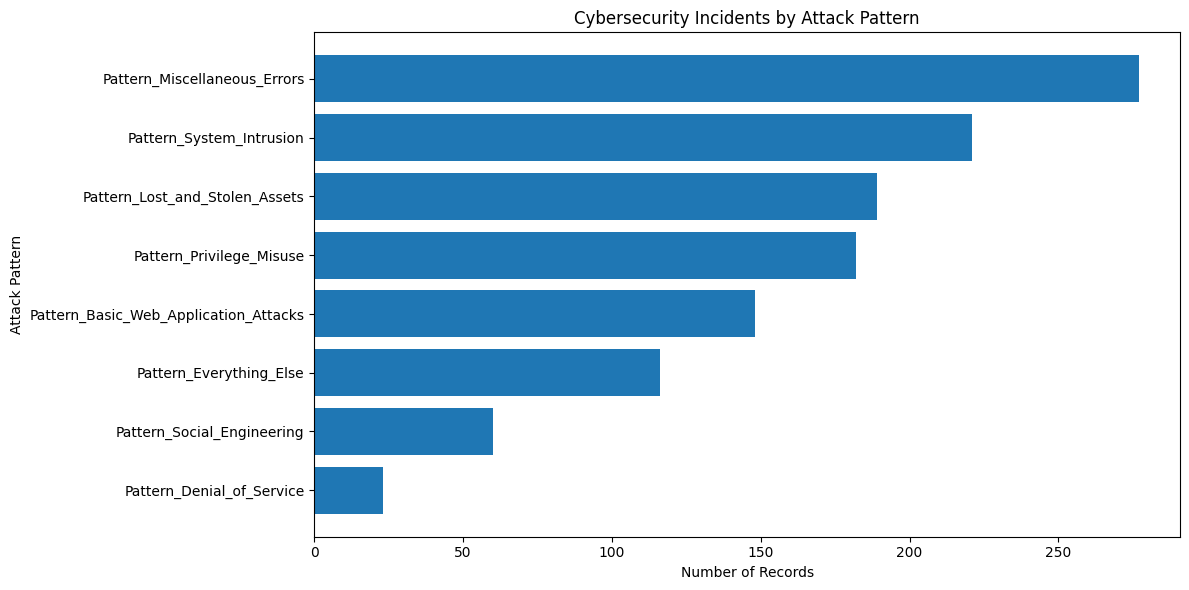

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    pattern_analysis["Attack_Pattern"],
    pattern_analysis["Incident_Count"]
)

plt.xlabel("Number of Records")
plt.ylabel("Attack Pattern")
plt.title("Cybersecurity Incidents by Attack Pattern")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:

# Count attacker categories
actor_analysis = (
    df_veris_final["Actor"]
    .value_counts(dropna=False)
    .reset_index()
)

actor_analysis.columns = ["Attacker_Type", "Record_Count"]

# Calculate percentage
actor_analysis["Percentage"] = (
    actor_analysis["Record_Count"] /
    len(df_veris_final) * 100
).round(2)

display(actor_analysis)


,Attacker_Type,Record_Count,Percentage
0,External,642,54.55
1,Internal,431,36.62
2,Partner,42,3.57
3,Multiple,35,2.97
4,<NA>,27,2.29


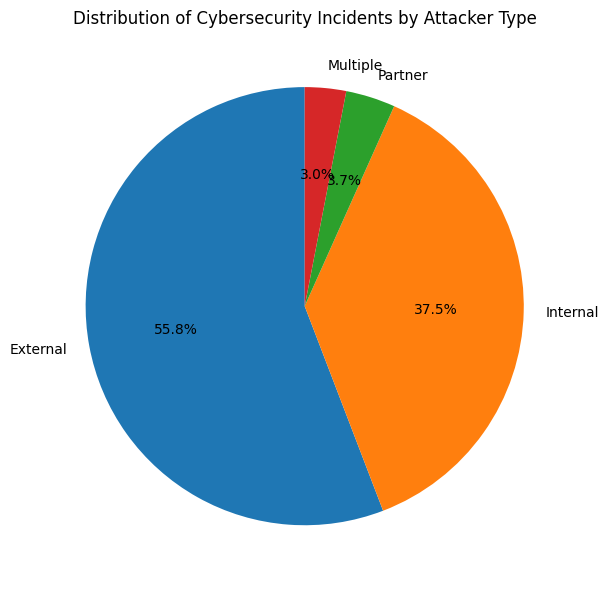

In [ ]:

import matplotlib.pyplot as plt

# Exclude missing attacker values from the chart
actor_chart = (
    df_veris_final["Actor"]
    .value_counts()
)

plt.figure(figsize=(8, 6))

plt.pie(
    actor_chart.values,
    labels=actor_chart.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Cybersecurity Incidents by Attacker Type")
plt.tight_layout()
plt.show()


In [ ]:

# Group attack patterns by attacker type
actor_pattern_analysis = (
    df_veris_final
    .groupby("Actor")[pattern_columns]
    .sum()
    .T
)

display(actor_pattern_analysis)


Actor,External,Internal,Multiple,Partner
Pattern_Privilege_Misuse,2,154,16,10
Pattern_Miscellaneous_Errors,3,240,8,25
Pattern_Lost_and_Stolen_Assets,129,38,8,10
Pattern_Basic_Web_Application_Attacks,145,1,0,0
Pattern_System_Intrusion,218,0,2,0
Pattern_Social_Engineering,53,1,5,1
Pattern_Denial_of_Service,23,0,0,0
Pattern_Everything_Else,92,6,0,0


In [ ]:

# Count records by primary victim industry
industry_analysis = (
    df_veris_final["Victim_Industry"]
    .value_counts()
    .reset_index()
)

industry_analysis.columns = [
    "Industry_Code",
    "Record_Count"
]

# Calculate percentage of all records
industry_analysis["Percentage"] = (
    industry_analysis["Record_Count"] /
    len(df_veris_final) * 100
).round(2)

display(industry_analysis.head(15))


,Industry_Code,Record_Count,Percentage
0,611310,120,10.2
1,622110,104,8.84
2,923140,98,8.33
3,621111,55,4.67
4,522110,27,2.29
5,92,24,2.04
6,0,21,1.78
7,921110,20,1.7
8,524114,19,1.61
9,447110,17,1.44


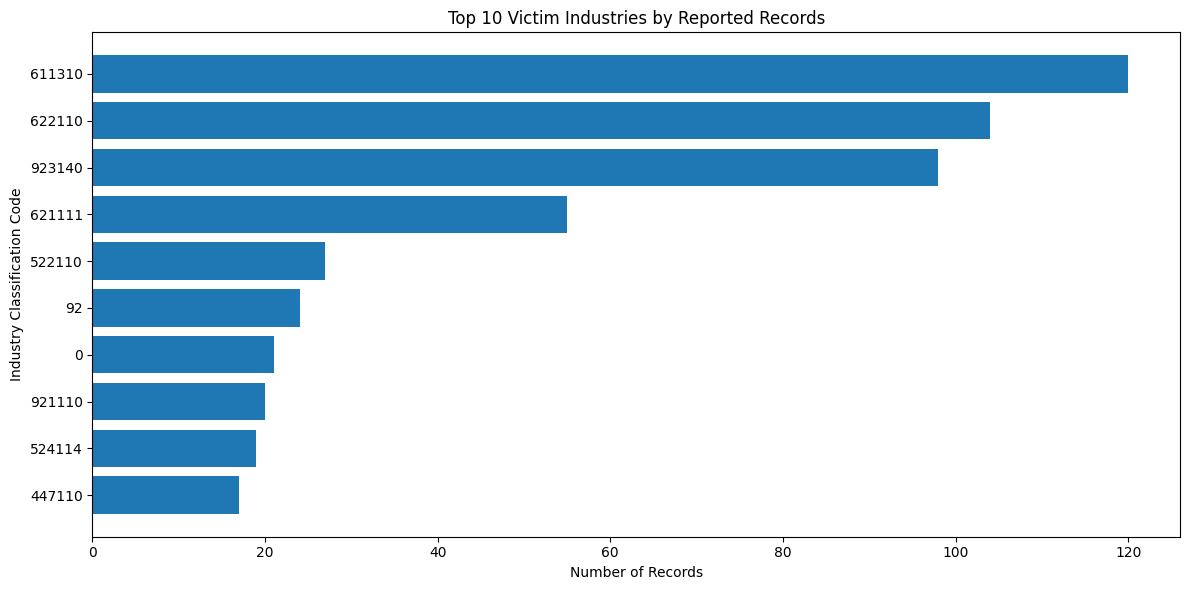

In [ ]:

import matplotlib.pyplot as plt

top_10_industries = industry_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_industries["Industry_Code"].astype(str),
    top_10_industries["Record_Count"]
)

plt.xlabel("Number of Records")
plt.ylabel("Industry Classification Code")
plt.title("Top 10 Victim Industries by Reported Records")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:

secondary_industry_analysis = (
    df_veris_final["Victim_Industry_Secondary"]
    .value_counts()
    .reset_index()
)

secondary_industry_analysis.columns = [
    "Secondary_Industry_Code",
    "Record_Count"
]

secondary_industry_analysis["Percentage"] = (
    secondary_industry_analysis["Record_Count"] /
    len(df_veris_final) * 100
).round(2)

display(secondary_industry_analysis.head(15))


,Secondary_Industry_Code,Record_Count,Percentage
0,62,277,23.53
1,92,269,22.85
2,61,144,12.23
3,52,110,9.35
4,51,89,7.56
5,54,50,4.25
6,44,46,3.91
7,81,27,2.29
8,72,27,2.29
9,0,21,1.78


In [ ]:

print(
    "Missing Primary Industry:",
    df_veris_final["Victim_Industry"].isna().sum()
)

print(
    "Missing Secondary Industry:",
    df_veris_final["Victim_Industry_Secondary"].isna().sum()
)

print(
    "Records with both industry codes:",
    df_veris_final[
        ["Victim_Industry", "Victim_Industry_Secondary"]
    ].notna().all(axis=1).sum()
)


Missing Primary Industry: 1
Missing Secondary Industry: 1
Records with both industry codes: 1176


In [ ]:

# Count records by victim region
region_analysis = (
    df_veris_final["Victim_Region"]
    .value_counts()
    .reset_index()
)

region_analysis.columns = [
    "Victim_Region",
    "Record_Count"
]

region_analysis["Percentage"] = (
    region_analysis["Record_Count"] /
    len(df_veris_final) * 100
).round(2)

display(region_analysis.head(15))


,Victim_Region,Record_Count,Percentage
0,019021,907,77.06
1,150154,73,6.2
2,009053,29,2.46
3,142030,23,1.95
4,142145,18,1.53
5,142034,15,1.27
6,150155,14,1.19
7,000000,13,1.1
8,142035,10,0.85
9,150151,10,0.85


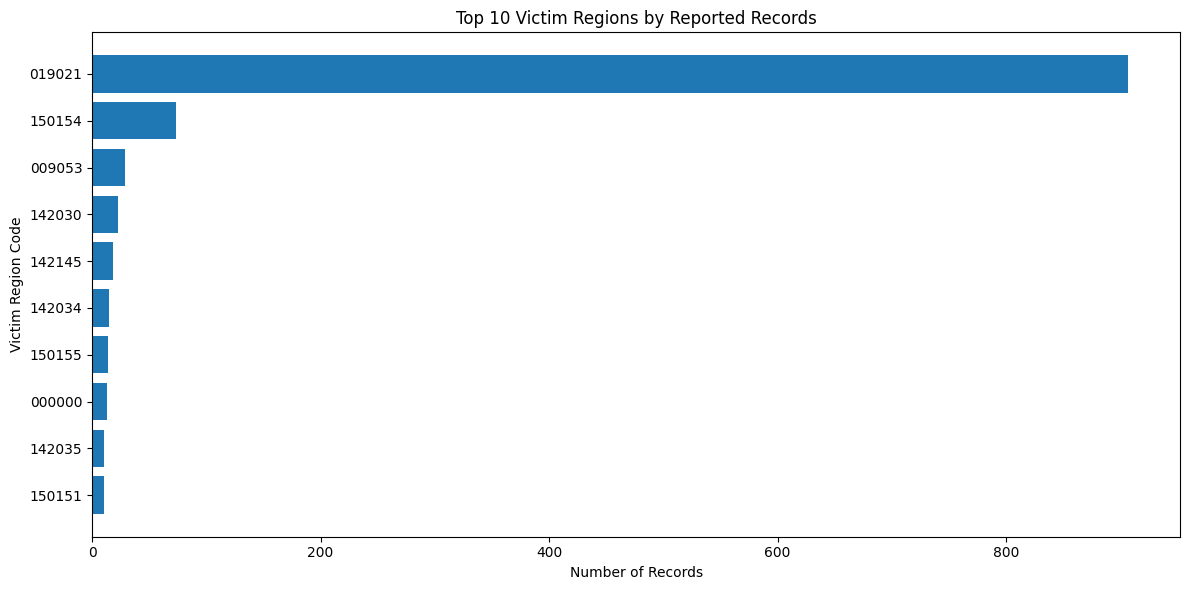

In [ ]:

import matplotlib.pyplot as plt

top_10_regions = region_analysis.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_regions["Victim_Region"],
    top_10_regions["Record_Count"]
)

plt.xlabel("Number of Records")
plt.ylabel("Victim Region Code")
plt.title("Top 10 Victim Regions by Reported Records")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:

# Identify records with multiple region codes
multiple_region_records = df_veris_final[
    df_veris_final["Victim_Region"].str.contains(
        ",", na=False
    )
]

print(
    "Records with multiple region codes:",
    len(multiple_region_records)
)

display(
    multiple_region_records[
        ["Incident_ID", "Victim_Region"]
    ].head(15)
)


Records with multiple region codes: 37


,Incident_ID,Victim_Region
6,9eda6e80-de98-11e7-9424-7b935f12be98,"019201,019021"
85,021E91A0-7159-4675-80CF-E618C2E498FF,"019021,021000"
86,b884eea0-ffd4-11e9-ad81-39b9e5fce51c,"150039,150151"
88,022CCB00-CE98-4DEF-8B89-18C5A20335F4,"021000,019021"
91,c2531320-2b4a-11ea-9dc8-9fe5cd17ac1d,"142034,142035"
171,22d1a2d0-2397-11eb-a2fc-cdee479fbead,"142035,143035"
297,a0e76430-0236-11ea-ad43-7952870528d4,"150154,150155"
362,76221690-1465-11eb-ac54-3bea5c26f172,"150154,150155"
384,47209780-1574-11eb-b788-65a639ed21e8,"142145,150039"
386,09390A4C-F45F-47D9-AED8-555A58743A34,"142145,150151"


In [ ]:

print(
    "Missing region values:",
    df_veris_final["Victim_Region"].isna().sum()
)

print(
    "Available region values:",
    df_veris_final["Victim_Region"].notna().sum()
)

print(
    "Unique region combinations:",
    df_veris_final["Victim_Region"].nunique()
)


Missing region values: 2
Available region values: 1175
Unique region combinations: 40


In [ ]:

# Count records by incident year
yearly_analysis = (
    df_veris_final["Incident_Year"]
    .dropna()
    .value_counts()
    .sort_index()
    .reset_index()
)

yearly_analysis.columns = [
    "Incident_Year",
    "Record_Count"
]

display(yearly_analysis)


,Incident_Year,Record_Count
0,1971,1
1,1998,1
2,2001,1
3,2003,1
4,2004,1
5,2005,3
6,2006,6
7,2007,8
8,2008,7
9,2009,11


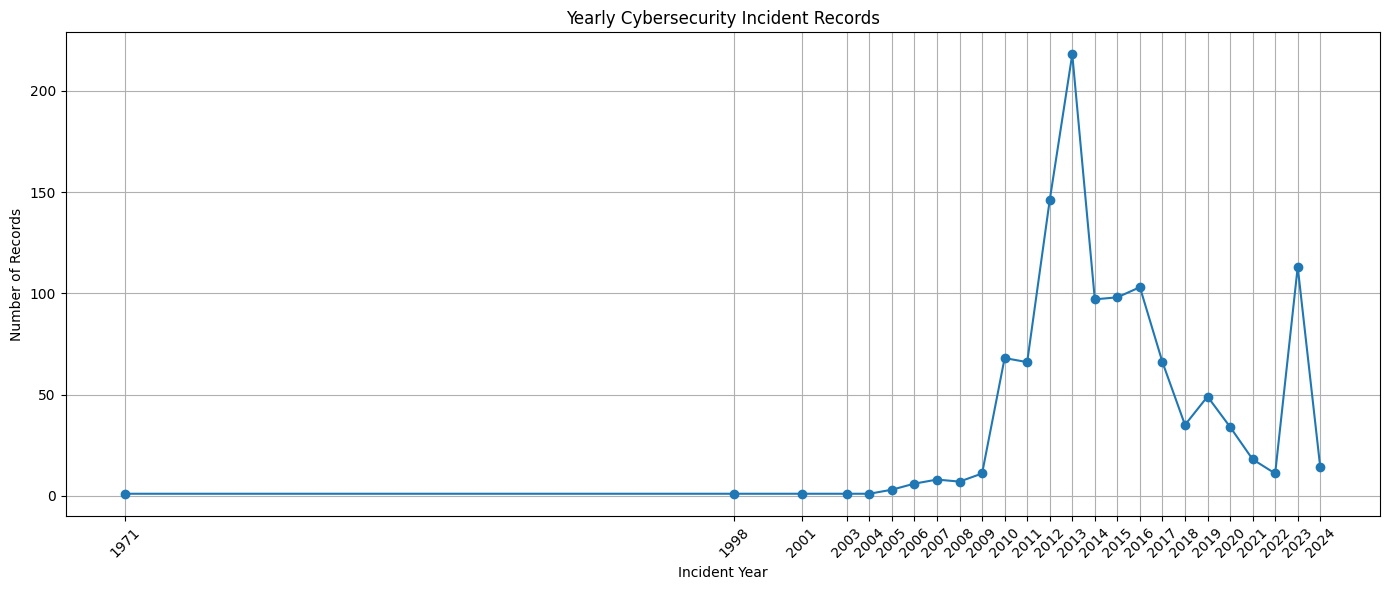

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    yearly_analysis["Incident_Year"],
    yearly_analysis["Record_Count"],
    marker="o"
)

plt.xlabel("Incident Year")
plt.ylabel("Number of Records")
plt.title("Yearly Cybersecurity Incident Records")

plt.xticks(
    yearly_analysis["Incident_Year"],
    rotation=45
)

plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

top_5_years = yearly_analysis.sort_values(
    by="Record_Count",
    ascending=False
).head(5)

display(top_5_years)


,Incident_Year,Record_Count
13,2013,218
12,2012,146
23,2023,113
16,2016,103
15,2015,98


In [ ]:

monthly_analysis = (
    df_veris_final["Incident_Month"]
    .dropna()
    .value_counts()
    .sort_index()
    .reset_index()
)

monthly_analysis.columns = [
    "Incident_Month",
    "Record_Count"
]

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_analysis["Month_Name"] = (
    monthly_analysis["Incident_Month"].map(month_names)
)

display(monthly_analysis)


,Incident_Month,Record_Count,Month_Name
0,1,73,January
1,2,62,February
2,3,68,March
3,4,63,April
4,5,60,May
5,6,171,June
6,7,61,July
7,8,54,August
8,9,64,September
9,10,68,October


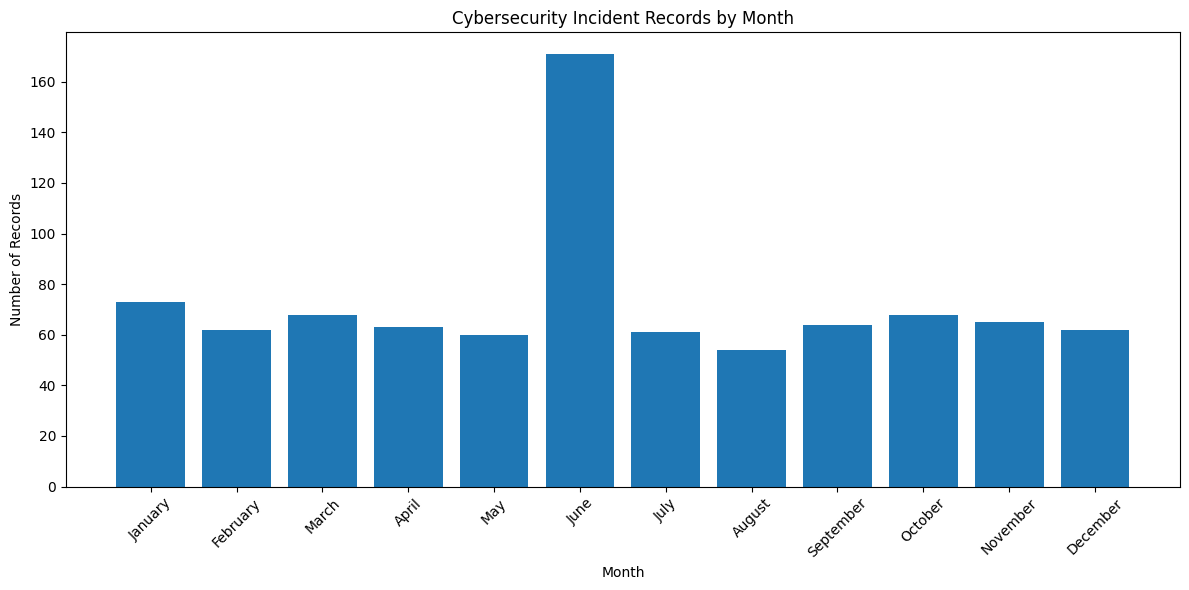

In [ ]:

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_analysis["Month_Name"],
    monthly_analysis["Record_Count"]
)

plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.title("Cybersecurity Incident Records by Month")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
top_industry_codes = (
    df_veris_final["Victim_Industry"]
    .value_counts()
    .head(10)
    .index
)

print("Top 10 Industry Codes:")
print(top_industry_codes.tolist())

Top 10 Industry Codes:
['611310', '622110', '923140', '621111', '522110', '92', '0', '921110', '524114', '447110']


In [ ]:
industry_pattern_data = df_veris_final[
    df_veris_final["Victim_Industry"].isin(top_industry_codes)
]

industry_pattern_analysis = (
    industry_pattern_data
    .groupby("Victim_Industry")[pattern_columns]
    .sum()
)

display(industry_pattern_analysis)

,Pattern_Privilege_Misuse,Pattern_Miscellaneous_Errors,Pattern_Lost_and_Stolen_Assets,Pattern_Basic_Web_Application_Attacks,Pattern_System_Intrusion,Pattern_Social_Engineering,Pattern_Denial_of_Service,Pattern_Everything_Else
Victim_Industry,,,,,,,,
0,1,4,2,6,2,1,5,1
447110,0,0,1,0,0,0,0,16
522110,6,3,2,1,5,2,0,10
524114,2,7,2,2,1,0,0,5
611310,3,9,5,8,89,2,3,4
621111,10,10,23,2,4,1,0,5
622110,26,24,29,2,12,7,0,5
92,3,7,2,5,3,3,1,2
921110,2,8,0,7,2,2,1,0


In [ ]:
simple_pattern_names = {
    "Pattern_Privilege_Misuse": "Privilege Misuse",
    "Pattern_Miscellaneous_Errors": "Miscellaneous Errors",
    "Pattern_Lost_and_Stolen_Assets": "Lost/Stolen Assets",
    "Pattern_Basic_Web_Application_Attacks": "Web Attacks",
    "Pattern_System_Intrusion": "System Intrusion",
    "Pattern_Social_Engineering": "Social Engineering",
    "Pattern_Denial_of_Service": "Denial of Service",
    "Pattern_Everything_Else": "Other Attacks"
}

industry_pattern_analysis = industry_pattern_analysis.rename(
    columns=simple_pattern_names
)

display(industry_pattern_analysis)

,Privilege Misuse,Miscellaneous Errors,Lost/Stolen Assets,Web Attacks,System Intrusion,Social Engineering,Denial of Service,Other Attacks
Victim_Industry,,,,,,,,
0,1,4,2,6,2,1,5,1
447110,0,0,1,0,0,0,0,16
522110,6,3,2,1,5,2,0,10
524114,2,7,2,2,1,0,0,5
611310,3,9,5,8,89,2,3,4
621111,10,10,23,2,4,1,0,5
622110,26,24,29,2,12,7,0,5
92,3,7,2,5,3,3,1,2
921110,2,8,0,7,2,2,1,0


In [ ]:
industry_pattern_numeric = (
    industry_pattern_analysis
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
    .astype(float)
)

display(industry_pattern_numeric)

,Privilege Misuse,Miscellaneous Errors,Lost/Stolen Assets,Web Attacks,System Intrusion,Social Engineering,Denial of Service,Other Attacks
Victim_Industry,,,,,,,,
0,1.0,4.0,2.0,6.0,2.0,1.0,5.0,1.0
447110,0.0,0.0,1.0,0.0,0.0,0.0,0.0,16.0
522110,6.0,3.0,2.0,1.0,5.0,2.0,0.0,10.0
524114,2.0,7.0,2.0,2.0,1.0,0.0,0.0,5.0
611310,3.0,9.0,5.0,8.0,89.0,2.0,3.0,4.0
621111,10.0,10.0,23.0,2.0,4.0,1.0,0.0,5.0
622110,26.0,24.0,29.0,2.0,12.0,7.0,0.0,5.0
92,3.0,7.0,2.0,5.0,3.0,3.0,1.0,2.0
921110,2.0,8.0,0.0,7.0,2.0,2.0,1.0,0.0


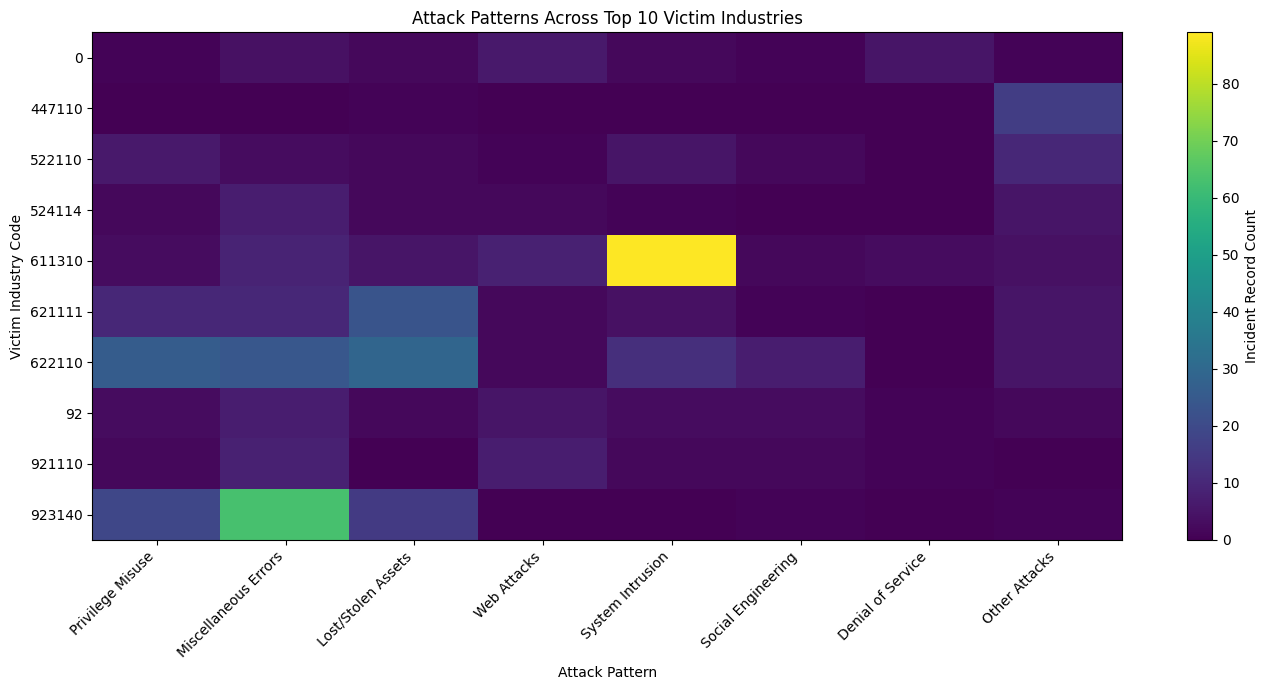

In [ ]:
plt.figure(figsize=(14, 7))

plt.imshow(industry_pattern_numeric, aspect="auto")
plt.colorbar(label="Incident Record Count")

plt.xticks(
    range(len(industry_pattern_numeric.columns)),
    industry_pattern_numeric.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(industry_pattern_numeric.index)),
    industry_pattern_numeric.index.astype(str)
)

plt.xlabel("Attack Pattern")
plt.ylabel("Victim Industry Code")
plt.title("Attack Patterns Across Top 10 Victim Industries")

plt.tight_layout()
plt.show()

In [ ]:
pattern_binary = (
    df_veris_final[pattern_columns]
    .fillna(False)
    .astype(bool)
    .rename(columns=simple_pattern_names)
)

display(pattern_binary.head())

,Privilege Misuse,Miscellaneous Errors,Lost/Stolen Assets,Web Attacks,System Intrusion,Social Engineering,Denial of Service,Other Attacks
0,True,False,False,False,False,False,False,False
1,False,True,False,False,False,False,False,False
2,False,False,True,False,False,False,False,False
3,False,False,True,False,False,False,False,False
4,False,False,False,True,False,False,False,False


In [ ]:
from itertools import combinations

pattern_combinations = []

for pattern1, pattern2 in combinations(pattern_binary.columns, 2):

    count = (
        pattern_binary[pattern1] &
        pattern_binary[pattern2]
    ).sum()

    pattern_combinations.append({
        "Pattern_1": pattern1,
        "Pattern_2": pattern2,
        "Incident_Count": count
    })

pattern_combination_analysis = pd.DataFrame(pattern_combinations)

pattern_combination_analysis = (
    pattern_combination_analysis
    .sort_values("Incident_Count", ascending=False)
    .reset_index(drop=True)
)

display(pattern_combination_analysis.head(15))

,Pattern_1,Pattern_2,Incident_Count
0,Miscellaneous Errors,Lost/Stolen Assets,12
1,Web Attacks,Denial of Service,9
2,Web Attacks,System Intrusion,8
3,System Intrusion,Social Engineering,5
4,Privilege Misuse,Social Engineering,4
5,Web Attacks,Social Engineering,2
6,System Intrusion,Denial of Service,1
7,Social Engineering,Denial of Service,1
8,Privilege Misuse,Miscellaneous Errors,1
9,Privilege Misuse,Web Attacks,0


In [ ]:
import json
import pandas as pd

file_path = "known_exploited_vulnerabilities.json"

with open(file_path, "r", encoding="utf-8") as file:
    data = json.load(file)

df_kev = pd.DataFrame(data["vulnerabilities"])

print("Original Dataset Shape:", df_kev.shape)
display(df_kev.head())

Original Dataset Shape: (1781, 12)


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes
0,CVE-2026-114713,UnrealIRCd,UnrealIRCd,UnrealIRCd Improper Neutralization of Delimite...,2026-11-13,UnrealIRCd UnrealIRCd contains an improper neu...,Apply mitigations in accordance with vendor in...,2026-11-16,Unknown,Yes,https://forums.unrealircd.org/viewtopic.php?t=...,[CWE-140]
1,CVE-2026-123039,Check Point,Multiple Products,Check Point Multiple Products Incorrect Permis...,2026-11-13,"Check Point Firewall, Multi-Domain Security Ma...",Apply mitigations in accordance with vendor in...,2026-11-16,Unknown,Yes,https://support.checkpoint.com/results/sk/sk10...,"[CWE-732, CWE-862]"
2,CVE-2026-124194,Microsoft,Office,Microsoft Office Outlook Missing User Interact...,2026-11-10,Microsoft Office Outlook contains a missing us...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://msrc.microsoft.com/update-guide/en-US/...,[CWE-356]
3,CVE-2026-111793,Openwave Messaging Limited,Webtop Media Transcoder,Openwave Messaging Limited Webtop Media Transc...,2026-11-10,Openwave Messaging Limited Webtop Media Transc...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://github.com/GISOpenwave/security-adviso...,[CWE-669]
4,CVE-2026-20320,Cisco,BroadWorks,Cisco BroadWorks Improper Restriction of XML E...,2026-11-10,Cisco BroadWorks contains an improper restrict...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://sec.cloudapps.cisco.com/security/cente...,[CWE-611]


In [ ]:
df_kev_clean = df_kev.copy()

df_kev_clean["dateAdded"] = pd.to_datetime(
    df_kev_clean["dateAdded"], errors="coerce"
)

df_kev_clean["dueDate"] = pd.to_datetime(
    df_kev_clean["dueDate"], errors="coerce"
)

df_kev_clean = (
    df_kev_clean
    .drop_duplicates(subset=["cveID"])
    .reset_index(drop=True)
)

print("Cleaned Dataset Shape:", df_kev_clean.shape)
display(df_kev_clean.head())

Cleaned Dataset Shape: (1781, 12)


,cveID,vendorProject,product,vulnerabilityName,dateAdded,shortDescription,requiredAction,dueDate,knownRansomwareCampaignUse,forensicTriage,notes,cwes
0,CVE-2026-114713,UnrealIRCd,UnrealIRCd,UnrealIRCd Improper Neutralization of Delimite...,2026-11-13,UnrealIRCd UnrealIRCd contains an improper neu...,Apply mitigations in accordance with vendor in...,2026-11-16,Unknown,Yes,https://forums.unrealircd.org/viewtopic.php?t=...,[CWE-140]
1,CVE-2026-123039,Check Point,Multiple Products,Check Point Multiple Products Incorrect Permis...,2026-11-13,"Check Point Firewall, Multi-Domain Security Ma...",Apply mitigations in accordance with vendor in...,2026-11-16,Unknown,Yes,https://support.checkpoint.com/results/sk/sk10...,"[CWE-732, CWE-862]"
2,CVE-2026-124194,Microsoft,Office,Microsoft Office Outlook Missing User Interact...,2026-11-10,Microsoft Office Outlook contains a missing us...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://msrc.microsoft.com/update-guide/en-US/...,[CWE-356]
3,CVE-2026-111793,Openwave Messaging Limited,Webtop Media Transcoder,Openwave Messaging Limited Webtop Media Transc...,2026-11-10,Openwave Messaging Limited Webtop Media Transc...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://github.com/GISOpenwave/security-adviso...,[CWE-669]
4,CVE-2026-20320,Cisco,BroadWorks,Cisco BroadWorks Improper Restriction of XML E...,2026-11-10,Cisco BroadWorks contains an improper restrict...,Apply mitigations in accordance with vendor in...,2026-11-24,Unknown,No,https://sec.cloudapps.cisco.com/security/cente...,[CWE-611]


In [ ]:
print("Dataset Shape:", df_kev_clean.shape)

print("\nColumn Names:")
print(df_kev_clean.columns.tolist())

print("\nDataset Information:")
df_kev_clean.info()

Dataset Shape: (1781, 12)

Column Names:
['cveID', 'vendorProject', 'product', 'vulnerabilityName', 'dateAdded', 'shortDescription', 'requiredAction', 'dueDate', 'knownRansomwareCampaignUse', 'forensicTriage', 'notes', 'cwes']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1781 entries, 0 to 1780
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   cveID                       1781 non-null   object        
 1   vendorProject               1781 non-null   object        
 2   product                     1781 non-null   object        
 3   vulnerabilityName           1781 non-null   object        
 4   dateAdded                   1781 non-null   datetime64[ns]
 5   shortDescription            1781 non-null   object        
 6   requiredAction              1781 non-null   object        
 7   dueDate                     1781 non-null   datetime64[ns]
 8  

In [ ]:
missing_analysis = pd.DataFrame({
    "Column_Name": df_kev_clean.columns,
    "Missing_Values": df_kev_clean.isnull().sum().values,
    "Missing_Percentage": (
        df_kev_clean.isnull().mean().values * 100
    ).round(2)
})

missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
).reset_index(drop=True)

display(missing_analysis)

,Column_Name,Missing_Values,Missing_Percentage
0,cveID,0,0.0
1,vendorProject,0,0.0
2,product,0,0.0
3,vulnerabilityName,0,0.0
4,dateAdded,0,0.0
5,shortDescription,0,0.0
6,requiredAction,0,0.0
7,dueDate,0,0.0
8,knownRansomwareCampaignUse,0,0.0
9,forensicTriage,0,0.0


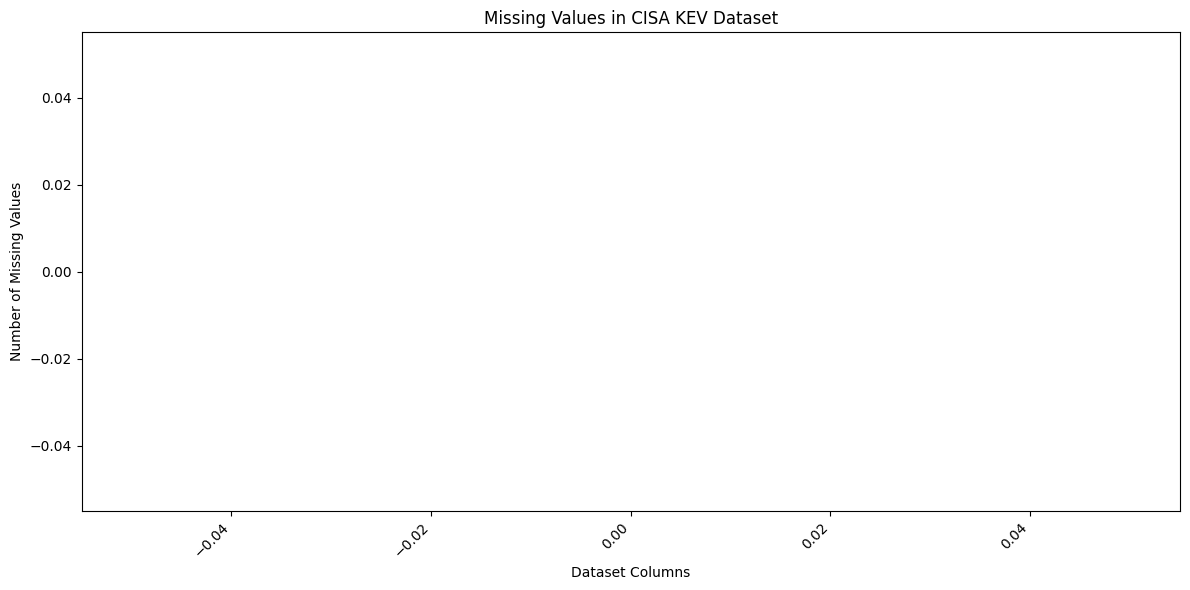

In [ ]:
import matplotlib.pyplot as plt

missing_data = missing_analysis[
    missing_analysis["Missing_Values"] > 0
]

plt.figure(figsize=(12, 6))

plt.bar(
    missing_data["Column_Name"],
    missing_data["Missing_Values"]
)

plt.xlabel("Dataset Columns")
plt.ylabel("Number of Missing Values")
plt.title("Missing Values in CISA KEV Dataset")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
print(
    "Duplicate CVE IDs:",
    df_kev_clean["cveID"].duplicated().sum()
)

print(
    "Unique CVE IDs:",
    df_kev_clean["cveID"].nunique()
)

Duplicate CVE IDs: 0
Unique CVE IDs: 1781


In [ ]:
print("Total Vulnerabilities:", len(df_kev_clean))

print(
    "Unique Vendors:",
    df_kev_clean["vendorProject"].nunique()
)

print(
    "Unique Products:",
    df_kev_clean["product"].nunique()
)

print(
    "Ransomware Campaign Values:"
)

display(
    df_kev_clean["knownRansomwareCampaignUse"]
    .value_counts(dropna=False)
)

Total Vulnerabilities: 1781
Unique Vendors: 295
Unique Products: 714
Ransomware Campaign Values:


,count
knownRansomwareCampaignUse,
Unknown,1420
Known,361


In [ ]:
vendor_analysis = (
    df_kev_clean["vendorProject"]
    .value_counts()
    .reset_index()
)

vendor_analysis.columns = [
    "Vendor",
    "Vulnerability_Count"
]

display(vendor_analysis.head(15))

,Vendor,Vulnerability_Count
0,Microsoft,391
1,Cisco,103
2,Apple,96
3,Adobe,83
4,Google,77
5,Oracle,46
6,Apache,41
7,Ivanti,38
8,Fortinet,32
9,Linux,32


In [ ]:
top_10_vendors = vendor_analysis.head(10)

display(top_10_vendors)

,Vendor,Vulnerability_Count
0,Microsoft,391
1,Cisco,103
2,Apple,96
3,Adobe,83
4,Google,77
5,Oracle,46
6,Apache,41
7,Ivanti,38
8,Fortinet,32
9,Linux,32


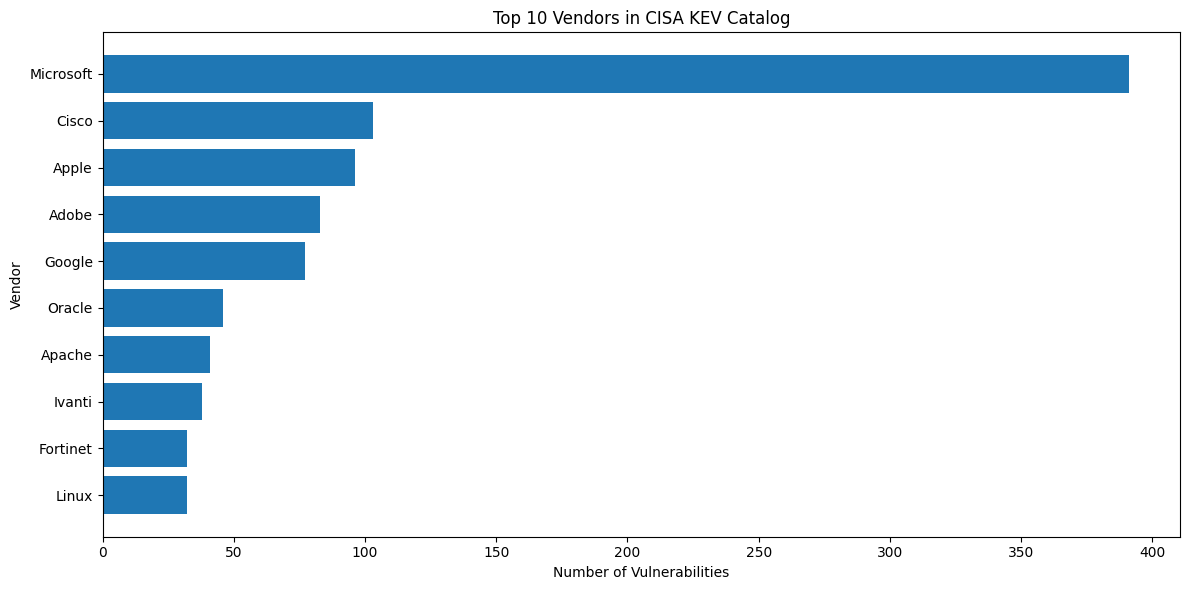

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_vendors["Vendor"],
    top_10_vendors["Vulnerability_Count"]
)

plt.xlabel("Number of Vulnerabilities")
plt.ylabel("Vendor")
plt.title("Top 10 Vendors in CISA KEV Catalog")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
vendor_analysis["Percentage"] = (
    vendor_analysis["Vulnerability_Count"] /
    len(df_kev_clean) * 100
).round(2)

display(vendor_analysis.head(15))

,Vendor,Vulnerability_Count,Percentage
0,Microsoft,391,21.95
1,Cisco,103,5.78
2,Apple,96,5.39
3,Adobe,83,4.66
4,Google,77,4.32
5,Oracle,46,2.58
6,Apache,41,2.30
7,Ivanti,38,2.13
8,Fortinet,32,1.80
9,Linux,32,1.80


In [ ]:
product_analysis = (
    df_kev_clean["product"]
    .value_counts()
    .reset_index()
)

product_analysis.columns = [
    "Product",
    "Vulnerability_Count"
]

display(product_analysis.head(15))

,Product,Vulnerability_Count
0,Windows,175
1,Multiple Products,89
2,Chromium V8,41
3,Internet Explorer,36
4,Kernel,35
5,Flash Player,33
6,Office,30
7,Win32k,25
8,Exchange Server,17
9,Zimbra Collaboration Suite (ZCS),17


In [ ]:
top_10_products = product_analysis.head(10)

display(top_10_products)

,Product,Vulnerability_Count
0,Windows,175
1,Multiple Products,89
2,Chromium V8,41
3,Internet Explorer,36
4,Kernel,35
5,Flash Player,33
6,Office,30
7,Win32k,25
8,Exchange Server,17
9,Zimbra Collaboration Suite (ZCS),17


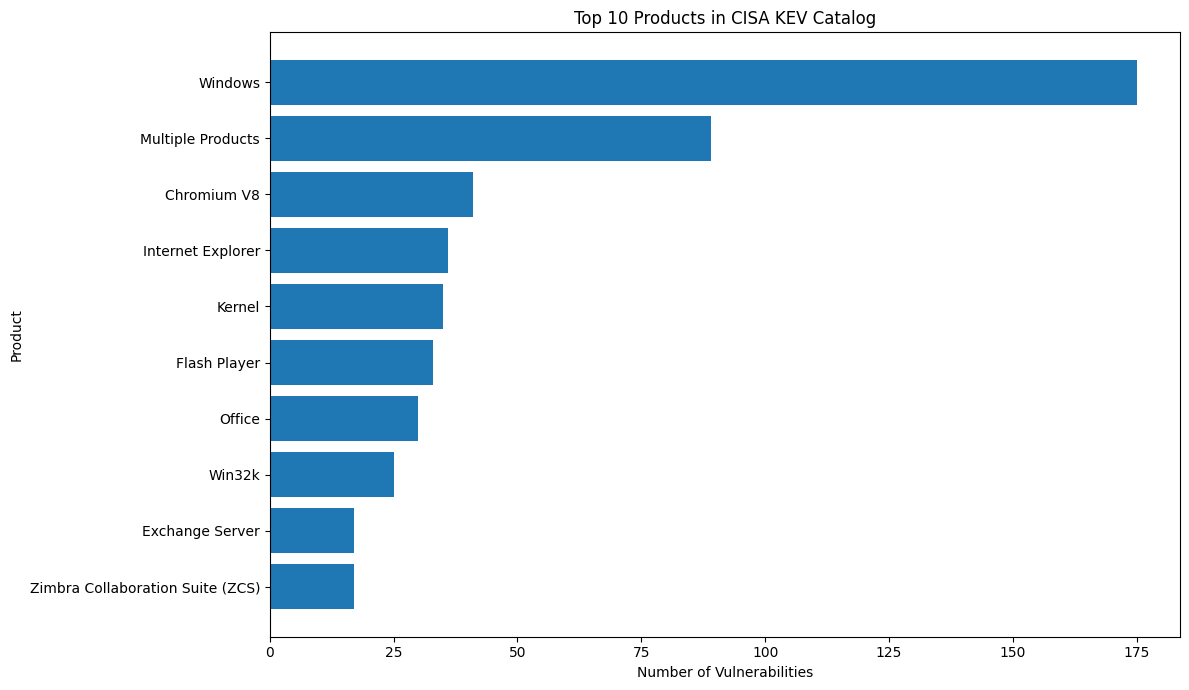

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_products["Product"],
    top_10_products["Vulnerability_Count"]
)

plt.xlabel("Number of Vulnerabilities")
plt.ylabel("Product")
plt.title("Top 10 Products in CISA KEV Catalog")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
vendor_product_analysis = (
    df_kev_clean
    .groupby(["vendorProject", "product"])
    .size()
    .reset_index(name="Vulnerability_Count")
    .sort_values(
        by="Vulnerability_Count",
        ascending=False
    )
    .reset_index(drop=True)
)

display(vendor_product_analysis.head(15))

,vendorProject,product,Vulnerability_Count
0,Microsoft,Windows,175
1,Apple,Multiple Products,55
2,Google,Chromium V8,41
3,Microsoft,Internet Explorer,36
4,Adobe,Flash Player,33
5,Linux,Kernel,32
6,Microsoft,Office,30
7,Microsoft,Win32k,25
8,Microsoft,Exchange Server,17
9,Synacor,Zimbra Collaboration Suite (ZCS),17


In [ ]:
ransomware_analysis = (
    df_kev_clean["knownRansomwareCampaignUse"]
    .value_counts(dropna=False)
    .reset_index()
)

ransomware_analysis.columns = [
    "Ransomware_Usage",
    "Vulnerability_Count"
]

display(ransomware_analysis)

,Ransomware_Usage,Vulnerability_Count
0,Unknown,1420
1,Known,361


In [ ]:
ransomware_analysis["Percentage"] = (
    ransomware_analysis["Vulnerability_Count"] /
    len(df_kev_clean) * 100
).round(2)

display(ransomware_analysis)

,Ransomware_Usage,Vulnerability_Count,Percentage
0,Unknown,1420,79.73
1,Known,361,20.27


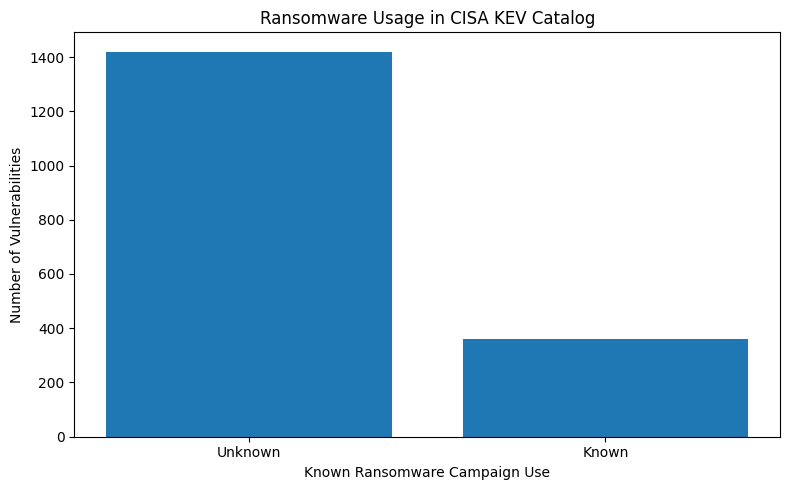

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    ransomware_analysis["Ransomware_Usage"].astype(str),
    ransomware_analysis["Vulnerability_Count"]
)

plt.xlabel("Known Ransomware Campaign Use")
plt.ylabel("Number of Vulnerabilities")
plt.title("Ransomware Usage in CISA KEV Catalog")

plt.tight_layout()
plt.show()

In [ ]:
ransomware_vulnerabilities = df_kev_clean[
    df_kev_clean["knownRansomwareCampaignUse"] == "Known"
].copy()

ransomware_vulnerabilities = ransomware_vulnerabilities[
    [
        "cveID",
        "vendorProject",
        "product",
        "vulnerabilityName",
        "dateAdded",
        "requiredAction",
        "dueDate"
    ]
]

display(ransomware_vulnerabilities.head(15))

,cveID,vendorProject,product,vulnerabilityName,dateAdded,requiredAction,dueDate
112,CVE-2026-59310,Broadcom,VMware vCenter,Broadcom VMware vCenter Path Traversal Vulnera...,2026-08-18,Apply mitigations in accordance with vendor in...,2026-08-21
120,CVE-2026-63077,JetBrains,TeamCity,JetBrains TeamCity Deserialization of Untruste...,2026-08-05,Apply mitigations in accordance with vendor in...,2026-08-08
125,CVE-2026-20316,Cisco,Secure Firewall Management Center (FMC),Cisco Secure Firewall Management Center Use of...,2026-07-29,Apply mitigations in accordance with vendor in...,2026-08-01
141,CVE-2026-15409,SonicWall,SMA1000 Appliances,SonicWall SMA1000 Appliances Server-Side Reque...,2026-07-14,Apply mitigations in accordance with vendor in...,2026-07-17
142,CVE-2026-15410,SonicWall,SMA1000 Appliances,SonicWall SMA1000 Appliances Code Injection Vu...,2026-07-14,Apply mitigations in accordance with vendor in...,2026-07-17
150,CVE-2026-45659,Microsoft,SharePoint Server,Microsoft SharePoint Server Deserialization of...,2026-07-01,Apply mitigations in accordance with vendor in...,2026-07-04
152,CVE-2026-12569,PTC,Windchill and FlexPLM,PTC Windchill and FlexPLM Improper Input Valid...,2026-06-25,Apply mitigations in accordance with vendor in...,2026-06-28
162,CVE-2026-35273,Oracle,PeopleSoft Enterprise PeopleTools,Oracle PeopleSoft Enterprise PeopleTools Missi...,2026-06-12,Apply mitigations in accordance with vendor in...,2026-06-15
168,CVE-2026-50751,Check Point,Security Gateway,Check Point Security Gateway Improper Authenti...,2026-06-08,"Apply mitigations per vendor instructions, fol...",2026-06-11
174,CVE-2026-0257,Palo Alto Networks,PAN-OS,Palo Alto Networks PAN-OS Authentication Bypas...,2026-05-29,"Apply mitigations per vendor instructions, fol...",2026-06-01


In [ ]:
ransomware_vendor_analysis = (
    ransomware_vulnerabilities["vendorProject"]
    .value_counts()
    .head(10)
    .reset_index()
)

ransomware_vendor_analysis.columns = [
    "Vendor",
    "Ransomware_Vulnerability_Count"
]

display(ransomware_vendor_analysis)

,Vendor,Ransomware_Vulnerability_Count
0,Microsoft,117
1,Fortinet,14
2,Oracle,13
3,SonicWall,13
4,Ivanti,12
5,Adobe,11
6,VMware,9
7,QNAP,9
8,Atlassian,8
9,Apache,8


In [ ]:
df_kev_clean["Added_Year"] = (
    df_kev_clean["dateAdded"].dt.year
)

yearly_kev_analysis = (
    df_kev_clean["Added_Year"]
    .value_counts()
    .sort_index()
    .reset_index()
)

yearly_kev_analysis.columns = [
    "Year",
    "Vulnerability_Count"
]

display(yearly_kev_analysis)

,Year,Vulnerability_Count
0,2021,311
1,2022,555
2,2023,187
3,2024,186
4,2025,245
5,2026,297


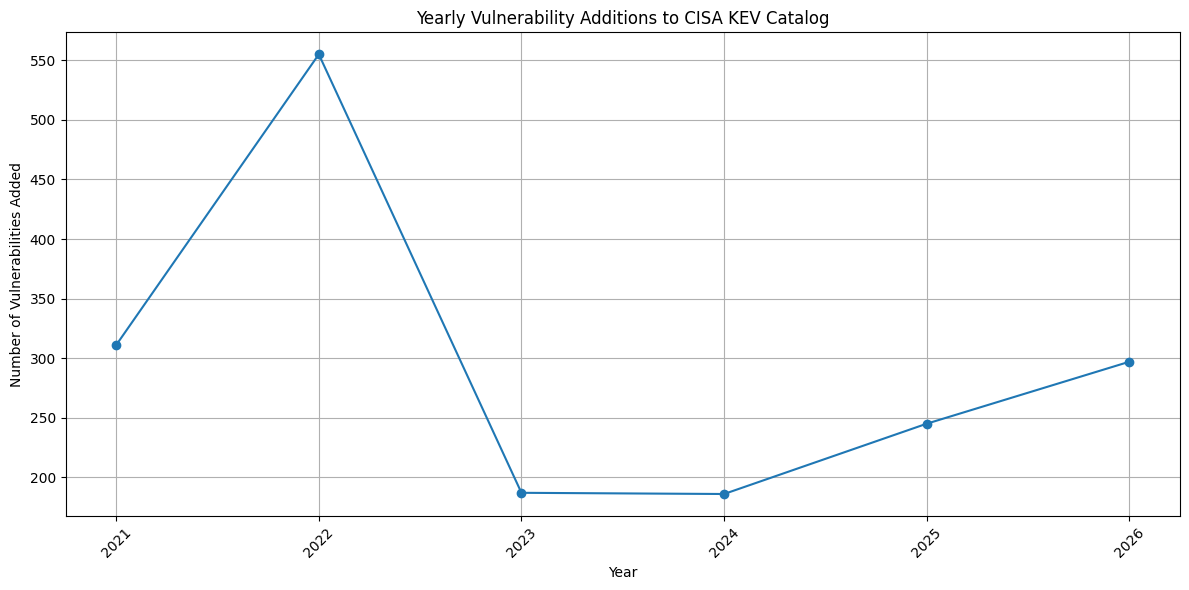

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_kev_analysis["Year"],
    yearly_kev_analysis["Vulnerability_Count"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of Vulnerabilities Added")
plt.title("Yearly Vulnerability Additions to CISA KEV Catalog")

plt.xticks(yearly_kev_analysis["Year"], rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
monthly_kev_analysis = (
    df_kev_clean["dateAdded"]
    .dt.month
    .value_counts()
    .sort_index()
    .reset_index()
)

monthly_kev_analysis.columns = [
    "Month",
    "Vulnerability_Count"
]

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly_kev_analysis["Month_Name"] = (
    monthly_kev_analysis["Month"].map(month_names)
)

display(monthly_kev_analysis)

,Month,Vulnerability_Count,Month_Name
0,1,97,January
1,2,110,February
2,3,312,March
3,4,118,April
4,5,161,May
5,6,124,June
6,7,79,July
7,8,96,August
8,9,127,September
9,10,114,October


In [ ]:
print(
    "Missing Remediation Deadlines:",
    df_kev_clean["dueDate"].isna().sum()
)

print(
    "Available Remediation Deadlines:",
    df_kev_clean["dueDate"].notna().sum()
)

display(
    df_kev_clean[
        ["cveID", "vendorProject", "product", "dateAdded", "dueDate"]
    ].head(15)
)

Missing Remediation Deadlines: 0
Available Remediation Deadlines: 1781


,cveID,vendorProject,product,dateAdded,dueDate
0,CVE-2026-114713,UnrealIRCd,UnrealIRCd,2026-11-13,2026-11-16
1,CVE-2026-123039,Check Point,Multiple Products,2026-11-13,2026-11-16
2,CVE-2026-124194,Microsoft,Office,2026-11-10,2026-11-24
3,CVE-2026-111793,Openwave Messaging Limited,Webtop Media Transcoder,2026-11-10,2026-11-24
4,CVE-2026-20320,Cisco,BroadWorks,2026-11-10,2026-11-24
5,CVE-2026-111560,Barracuda Networks,Multiple Products,2026-11-10,2026-11-13
6,CVE-2026-116606,Barracuda Networks,Barracuda Email Security Gateway (ESG),2026-11-10,2026-11-13
7,CVE-2026-125350,Google,Chromium,2026-11-10,2026-11-24
8,CVE-2026-102895,GPUStack,GPUStack,2026-11-09,2026-11-12
9,CVE-2026-123158,OpenBSD,OpenSSH,2026-11-09,2026-11-12


In [ ]:
df_kev_clean["Days_To_Remediation"] = (
    df_kev_clean["dueDate"] -
    df_kev_clean["dateAdded"]
).dt.days

display(
    df_kev_clean[
        ["cveID", "dateAdded", "dueDate", "Days_To_Remediation"]
    ].head(15)
)

,cveID,dateAdded,dueDate,Days_To_Remediation
0,CVE-2026-114713,2026-11-13,2026-11-16,3
1,CVE-2026-123039,2026-11-13,2026-11-16,3
2,CVE-2026-124194,2026-11-10,2026-11-24,14
3,CVE-2026-111793,2026-11-10,2026-11-24,14
4,CVE-2026-20320,2026-11-10,2026-11-24,14
5,CVE-2026-111560,2026-11-10,2026-11-13,3
6,CVE-2026-116606,2026-11-10,2026-11-13,3
7,CVE-2026-125350,2026-11-10,2026-11-24,14
8,CVE-2026-102895,2026-11-09,2026-11-12,3
9,CVE-2026-123158,2026-11-09,2026-11-12,3


In [ ]:
analysis_date = pd.Timestamp.today().normalize()

df_kev_clean["Remediation_Status"] = "Unknown Deadline"

df_kev_clean.loc[
    df_kev_clean["dueDate"] < analysis_date,
    "Remediation_Status"
] = "Deadline Passed"

df_kev_clean.loc[
    df_kev_clean["dueDate"] >= analysis_date,
    "Remediation_Status"
] = "Upcoming Deadline"

print("Analysis Date:", analysis_date.date())

display(
    df_kev_clean[
        ["cveID", "dateAdded", "dueDate", "Remediation_Status"]
    ].head(15)
)

Analysis Date: 2026-11-16


,cveID,dateAdded,dueDate,Remediation_Status
0,CVE-2026-114713,2026-11-13,2026-11-16,Upcoming Deadline
1,CVE-2026-123039,2026-11-13,2026-11-16,Upcoming Deadline
2,CVE-2026-124194,2026-11-10,2026-11-24,Upcoming Deadline
3,CVE-2026-111793,2026-11-10,2026-11-24,Upcoming Deadline
4,CVE-2026-20320,2026-11-10,2026-11-24,Upcoming Deadline
5,CVE-2026-111560,2026-11-10,2026-11-13,Deadline Passed
6,CVE-2026-116606,2026-11-10,2026-11-13,Deadline Passed
7,CVE-2026-125350,2026-11-10,2026-11-24,Upcoming Deadline
8,CVE-2026-102895,2026-11-09,2026-11-12,Deadline Passed
9,CVE-2026-123158,2026-11-09,2026-11-12,Deadline Passed


In [ ]:
remediation_analysis = (
    df_kev_clean["Remediation_Status"]
    .value_counts()
    .reset_index()
)

remediation_analysis.columns = [
    "Remediation_Status",
    "Vulnerability_Count"
]

remediation_analysis["Percentage"] = (
    remediation_analysis["Vulnerability_Count"] /
    len(df_kev_clean) * 100
).round(2)

display(remediation_analysis)

,Remediation_Status,Vulnerability_Count,Percentage
0,Deadline Passed,1773,99.55
1,Upcoming Deadline,8,0.45


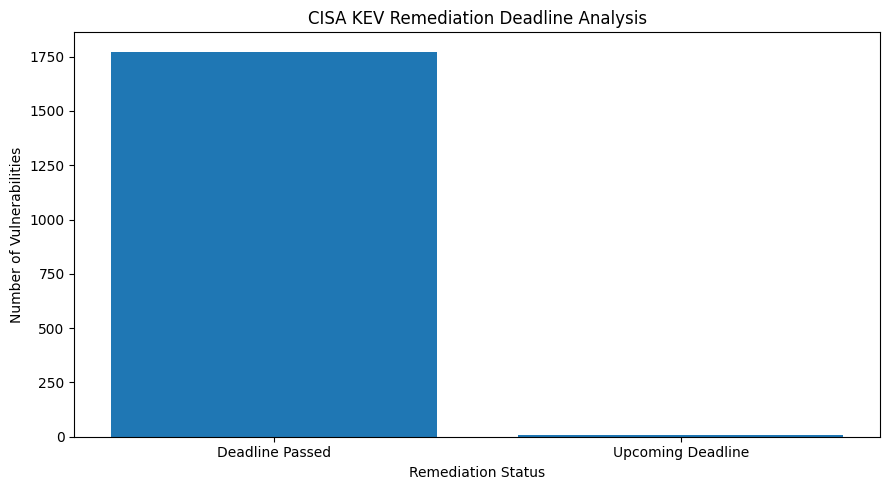

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    remediation_analysis["Remediation_Status"],
    remediation_analysis["Vulnerability_Count"]
)

plt.xlabel("Remediation Status")
plt.ylabel("Number of Vulnerabilities")
plt.title("CISA KEV Remediation Deadline Analysis")

plt.tight_layout()
plt.show()

In [ ]:
passed_deadlines = df_kev_clean[
    df_kev_clean["Remediation_Status"] == "Deadline Passed"
].copy()

passed_deadlines = passed_deadlines.sort_values(
    by="dueDate"
)

display(
    passed_deadlines[
        [
            "cveID",
            "vendorProject",
            "product",
            "dateAdded",
            "dueDate",
            "requiredAction"
        ]
    ].head(20)
)

,cveID,vendorProject,product,dateAdded,dueDate,requiredAction
1508,CVE-2021-42013,Apache,HTTP Server,2021-11-03,2021-11-17,Apply updates per vendor instructions.
1631,CVE-2021-31201,Microsoft,Enhanced Cryptographic Provider,2021-11-03,2021-11-17,Apply updates per vendor instructions.
1630,CVE-2021-31956,Microsoft,Windows,2021-11-03,2021-11-17,Apply updates per vendor instructions.
1629,CVE-2021-33771,Microsoft,Windows,2021-11-03,2021-11-17,Apply updates per vendor instructions.
1694,CVE-2021-36955,Microsoft,Windows,2021-11-03,2021-11-17,Apply updates per vendor instructions.
1695,CVE-2021-38648,Microsoft,Open Management Infrastructure (OMI),2021-11-03,2021-11-17,Apply updates per vendor instructions.
1628,CVE-2021-31199,Microsoft,Enhanced Cryptographic Provider,2021-11-03,2021-11-17,Apply updates per vendor instructions.
1627,CVE-2021-33742,Microsoft,Windows,2021-11-03,2021-11-17,Apply updates per vendor instructions.
1529,CVE-2021-1879,Apple,"iOS, iPadOS, and watchOS",2021-11-03,2021-11-17,Apply updates per vendor instructions.
1530,CVE-2021-30661,Apple,Multiple Products,2021-11-03,2021-11-17,Apply updates per vendor instructions.


In [ ]:
overdue_vendor_analysis = (
    passed_deadlines["vendorProject"]
    .value_counts()
    .head(10)
    .reset_index()
)

overdue_vendor_analysis.columns = [
    "Vendor",
    "Deadline_Passed_Count"
]

display(overdue_vendor_analysis)

,Vendor,Deadline_Passed_Count
0,Microsoft,390
1,Cisco,102
2,Apple,95
3,Adobe,83
4,Google,76
5,Oracle,46
6,Apache,41
7,Ivanti,38
8,Linux,32
9,Fortinet,32


In [ ]:
vulnerability_type_analysis = (
    df_kev_clean["vulnerabilityName"]
    .value_counts()
    .reset_index()
)

vulnerability_type_analysis.columns = [
    "Vulnerability_Type",
    "Vulnerability_Count"
]

display(vulnerability_type_analysis.head(15))

,Vulnerability_Type,Vulnerability_Count
0,Microsoft Win32k Privilege Escalation Vulnerab...,23
1,Google Chromium V8 Type Confusion Vulnerability,20
2,Apple Multiple Products Memory Corruption Vuln...,11
3,Microsoft Windows Kernel Privilege Escalation ...,11
4,Microsoft Windows Privilege Escalation Vulnera...,9
5,Microsoft Internet Explorer Memory Corruption ...,8
6,Microsoft Exchange Server Remote Code Executio...,8
7,Adobe Flash Player Use-After-Free Vulnerability,8
8,Microsoft Internet Explorer Use-After-Free Vul...,7
9,Cisco IOS and IOS XE Software SNMP Remote Code...,7


In [ ]:
vulnerability_type_analysis["Percentage"] = (
    vulnerability_type_analysis["Vulnerability_Count"] /
    len(df_kev_clean) * 100
).round(2)

display(vulnerability_type_analysis.head(15))

,Vulnerability_Type,Vulnerability_Count,Percentage
0,Microsoft Win32k Privilege Escalation Vulnerab...,23,1.29
1,Google Chromium V8 Type Confusion Vulnerability,20,1.12
2,Apple Multiple Products Memory Corruption Vuln...,11,0.62
3,Microsoft Windows Kernel Privilege Escalation ...,11,0.62
4,Microsoft Windows Privilege Escalation Vulnera...,9,0.51
5,Microsoft Internet Explorer Memory Corruption ...,8,0.45
6,Microsoft Exchange Server Remote Code Executio...,8,0.45
7,Adobe Flash Player Use-After-Free Vulnerability,8,0.45
8,Microsoft Internet Explorer Use-After-Free Vul...,7,0.39
9,Cisco IOS and IOS XE Software SNMP Remote Code...,7,0.39


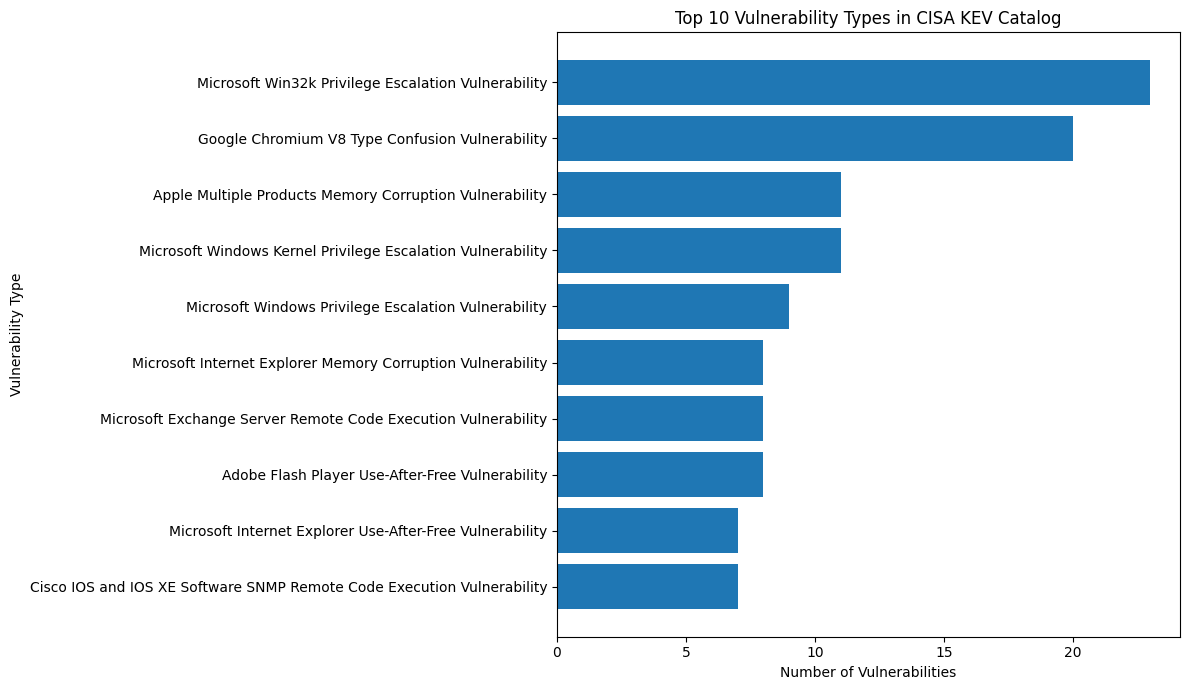

In [ ]:
top_10_vulnerability_types = (
    vulnerability_type_analysis.head(10)
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10_vulnerability_types["Vulnerability_Type"],
    top_10_vulnerability_types["Vulnerability_Count"]
)

plt.xlabel("Number of Vulnerabilities")
plt.ylabel("Vulnerability Type")
plt.title("Top 10 Vulnerability Types in CISA KEV Catalog")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
display(
    df_kev_clean[
        [
            "cveID",
            "vulnerabilityName",
            "shortDescription"
        ]
    ].head(15)
)

,cveID,vulnerabilityName,shortDescription
0,CVE-2026-114713,UnrealIRCd Improper Neutralization of Delimite...,UnrealIRCd UnrealIRCd contains an improper neu...
1,CVE-2026-123039,Check Point Multiple Products Incorrect Permis...,"Check Point Firewall, Multi-Domain Security Ma..."
2,CVE-2026-124194,Microsoft Office Outlook Missing User Interact...,Microsoft Office Outlook contains a missing us...
3,CVE-2026-111793,Openwave Messaging Limited Webtop Media Transc...,Openwave Messaging Limited Webtop Media Transc...
4,CVE-2026-20320,Cisco BroadWorks Improper Restriction of XML E...,Cisco BroadWorks contains an improper restrict...
5,CVE-2026-111560,Barracuda Networks Multiple Products OS Comman...,Barracuda Networks Email Security Gateway (ESG...
6,CVE-2026-116606,Barracuda Networks Email Security Gateway (ESG...,Barracuda Networks Email Security Gateway (ESG...
7,CVE-2026-125350,Google Chromium Use-After-Free Vulnerability,Google Chromium contains a use-after-free vuln...
8,CVE-2026-102895,GPUStack Improper Authentication Vulnerability,GPUStack contains an improper authentication v...
9,CVE-2026-123158,OpenBSD OpenSSH Unexpected Status Code or Retu...,OpenBSD OpenSSH on Linux contains an unexpecte...


In [ ]:
display(
    df_kev_clean[
        [
            "cveID",
            "vendorProject",
            "product",
            "requiredAction"
        ]
    ].head(15)
)

,cveID,vendorProject,product,requiredAction
0,CVE-2026-114713,UnrealIRCd,UnrealIRCd,Apply mitigations in accordance with vendor in...
1,CVE-2026-123039,Check Point,Multiple Products,Apply mitigations in accordance with vendor in...
2,CVE-2026-124194,Microsoft,Office,Apply mitigations in accordance with vendor in...
3,CVE-2026-111793,Openwave Messaging Limited,Webtop Media Transcoder,Apply mitigations in accordance with vendor in...
4,CVE-2026-20320,Cisco,BroadWorks,Apply mitigations in accordance with vendor in...
5,CVE-2026-111560,Barracuda Networks,Multiple Products,Apply mitigations in accordance with vendor in...
6,CVE-2026-116606,Barracuda Networks,Barracuda Email Security Gateway (ESG),Apply mitigations in accordance with vendor in...
7,CVE-2026-125350,Google,Chromium,Apply mitigations in accordance with vendor in...
8,CVE-2026-102895,GPUStack,GPUStack,Apply mitigations in accordance with vendor in...
9,CVE-2026-123158,OpenBSD,OpenSSH,Apply mitigations in accordance with vendor in...


In [ ]:
ransomware_vulnerabilities = df_kev_clean[
    df_kev_clean["knownRansomwareCampaignUse"] == "Known"
].copy()

print(
    "Known Ransomware Vulnerabilities:",
    len(ransomware_vulnerabilities)
)

Known Ransomware Vulnerabilities: 361


In [ ]:
high_priority_vulnerabilities = df_kev_clean[
    (df_kev_clean["knownRansomwareCampaignUse"] == "Known") &
    (df_kev_clean["dueDate"] < analysis_date)
].copy()

high_priority_vulnerabilities = (
    high_priority_vulnerabilities
    .sort_values("dueDate")
    .reset_index(drop=True)
)

print(
    "Vulnerabilities with Known Ransomware Use "
    "and Passed Deadlines:",
    len(high_priority_vulnerabilities)
)

display(
    high_priority_vulnerabilities[
        [
            "cveID",
            "vendorProject",
            "product",
            "vulnerabilityName",
            "dateAdded",
            "dueDate",
            "requiredAction"
        ]
    ].head(20)
)

Vulnerabilities with Known Ransomware Use and Passed Deadlines: 361


,cveID,vendorProject,product,vulnerabilityName,dateAdded,dueDate,requiredAction
0,CVE-2021-40539,Zoho,ManageEngine,Zoho ManageEngine ADSelfService Plus Authentic...,2021-11-03,2021-11-17,Apply updates per vendor instructions.
1,CVE-2021-41773,Apache,HTTP Server,Apache HTTP Server Path Traversal Vulnerability,2021-11-03,2021-11-17,Apply updates per vendor instructions.
2,CVE-2021-1675,Microsoft,Windows,Microsoft Windows Print Spooler Remote Code Ex...,2021-11-03,2021-11-17,Apply updates per vendor instructions.
3,CVE-2021-26084,Atlassian,Confluence Server and Data Center,Atlassian Confluence Server and Data Center Ob...,2021-11-03,2021-11-17,Apply updates per vendor instructions.
4,CVE-2021-42258,BQE,BillQuick Web Suite,BQE BillQuick Web Suite SQL Injection Vulnerab...,2021-11-03,2021-11-17,Apply updates per vendor instructions.
5,CVE-2021-22205,GitLab,Community and Enterprise Editions,GitLab Community and Enterprise Editions Remot...,2021-11-03,2021-11-17,Apply updates per vendor instructions.
6,CVE-2021-22986,F5,BIG-IP and BIG-IQ Centralized Management,F5 BIG-IP and BIG-IQ Centralized Management iC...,2021-11-03,2021-11-17,Apply updates per vendor instructions.
7,CVE-2021-42013,Apache,HTTP Server,Apache HTTP Server Path Traversal Vulnerability,2021-11-03,2021-11-17,Apply updates per vendor instructions.
8,CVE-2021-35464,ForgeRock,Access Management (AM),ForgeRock Access Management (AM) Core Server R...,2021-11-03,2021-11-17,Apply updates per vendor instructions.
9,CVE-2021-38647,Microsoft,Open Management Infrastructure (OMI),Microsoft Open Management Infrastructure (OMI)...,2021-11-03,2021-11-17,Apply updates per vendor instructions.


In [ ]:
priority_vendor_analysis = (
    high_priority_vulnerabilities["vendorProject"]
    .value_counts()
    .head(10)
    .reset_index()
)

priority_vendor_analysis.columns = [
    "Vendor",
    "Priority_Vulnerability_Count"
]

display(priority_vendor_analysis)

,Vendor,Priority_Vulnerability_Count
0,Microsoft,117
1,Fortinet,14
2,Oracle,13
3,SonicWall,13
4,Ivanti,12
5,Adobe,11
6,QNAP,9
7,VMware,9
8,Atlassian,8
9,Apache,8


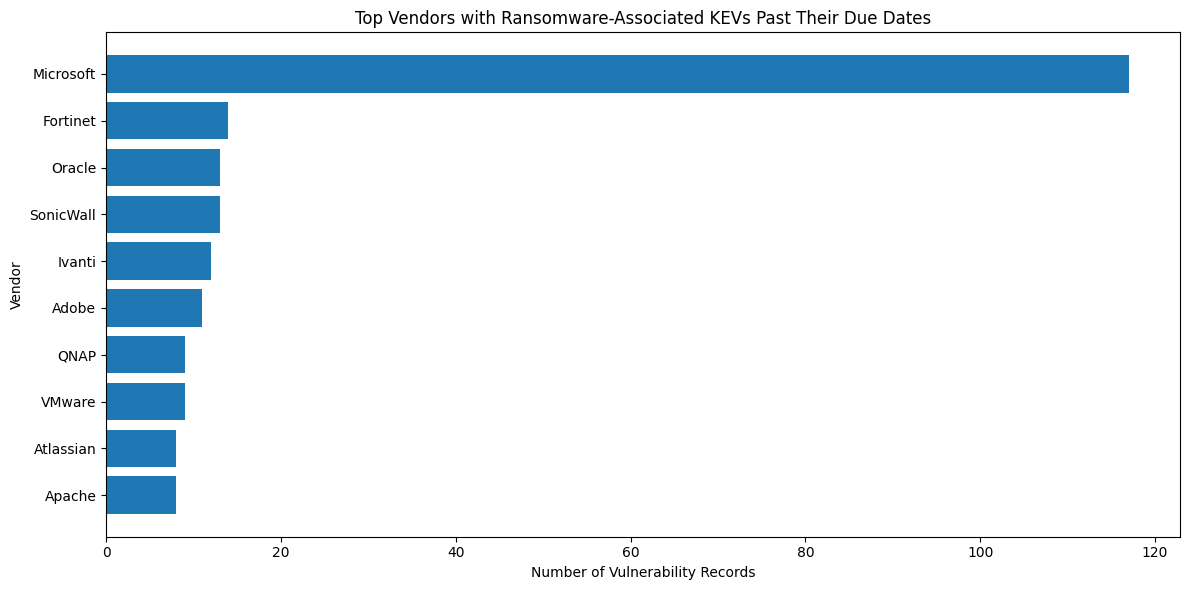

In [ ]:
plt.figure(figsize=(12, 6))

plt.barh(
    priority_vendor_analysis["Vendor"],
    priority_vendor_analysis["Priority_Vulnerability_Count"]
)

plt.xlabel("Number of Vulnerability Records")
plt.ylabel("Vendor")
plt.title("Top Vendors with Ransomware-Associated KEVs Past Their Due Dates")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
total_kev_records = len(df_kev_clean)

priority_count = len(high_priority_vulnerabilities)

priority_percentage = (
    priority_count / total_kev_records * 100
)

print("Total KEV Records:", total_kev_records)
print("Priority Records:", priority_count)
print("Percentage:", round(priority_percentage, 2), "%")

Total KEV Records: 1781
Priority Records: 361
Percentage: 20.27 %


In [ ]:
df_veris_final.to_csv("veris_incidents_clean.csv", index=False)
df_kev_clean.to_csv("cisa_kev_clean.csv", index=False)

print("Both CSV files saved successfully!")

Both CSV files saved successfully!
